# DATASCAPE 2026: E-Commerce Package Quality Control
Klasifikasi `Aman` / `Rusak` / `Lainnya` (Macro-F1). Alur: *decode* & *cache* citra → forensik near-duplicate (group CV + transfer label salinan) → head LR/MLP pada embedding 8 encoder citra beku + fine-tuning ConvNeXt-B dan PE-Core-L, semua dilatih pada label train panitia (+ pseudo-label otomatis dari salinan train) → post-processing. LB publik: **0,98075**.

## Cara menjalankan
- Letakkan notebook ini di folder yang berisi `sistemhitam_Requirements_Datascape.txt` dan `datasets/` (`Train_Set/`, `Test_Set/`, `sample_submission.csv`).
- Python 3.12, GPU NVIDIA ≥ 12 GB (CUDA 12.8), RAM ±32 GB; instal semua paket dengan `pip install -r sistemhitam_Requirements_Datascape.txt` (termasuk PyTorch CUDA 12.8).
- Jalankan semua sel (*Run All*); output utama `submission.csv`. Dari nol ±12 jam (RTX 5070 Ti); jika semua cache `artifacts/` sudah ada, ±10 menit.
- Hanya data panitia yang dipakai. Model pretrained (aturan 9) dipakai lewat encoder citranya saja (CLIP HF: `get_image_features`), sebagai ekstraktor fitur atau backbone fine-tune dengan head 3 kelas baru. Encoder teks, prompt, dan LLM/VLM tidak dipakai; tidak ada pelabelan manual.

## 0. Setup

In [1]:
import os, sys, gc, json, time, hashlib, itertools, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = os.path.abspath(".")                  # folder proyek (berisi datasets/)
DATA = f"{ROOT}/data"; ART = f"{ROOT}/artifacts"
os.makedirs(ART, exist_ok=True); os.makedirs(f"{ART}/emb", exist_ok=True); os.makedirs(f"{ROOT}/src", exist_ok=True)
CLASSES = ["Aman", "Rusak", "Lainnya"]; C2I = {c: i for i, c in enumerate(CLASSES)}
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda": torch.cuda.set_per_process_memory_fraction(0.92)   # error yang jelas, bukan meluber ke shared memory (WDDM)
CACHE_SIZE = 448
print("torch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

def macro_f1(y, p): return f1_score(y, p, average="macro")

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 1. Audit file & pemuatan citra
File WEBP/PNG berekstensi `.jpg`, citra RGBA/P, dan EXIF orientation ditangani saat *decode*; file yang tidak bisa dibaca (1 AVIF) dibuang. Semua citra di-*cache* 448×448 (memmap `uint8`).

In [2]:
def load_rgb(path, size=CACHE_SIZE):
    im = Image.open(path)
    if im.format == "JPEG": im.draft("RGB", (size, size))      # decode JPEG besar langsung di resolusi lebih kecil
    im = ImageOps.exif_transpose(im)
    if im.mode in ("P", "LA", "PA"): im = im.convert("RGBA")
    if im.mode == "RGBA":                                      # transparansi -> latar putih
        bg = Image.new("RGB", im.size, (255, 255, 255)); bg.paste(im, mask=im.split()[-1]); im = bg
    return im.convert("RGB")

def build_meta_and_cache():
    rows = [("train", c, f"Train_Set/{c}/{f}", f) for c in CLASSES for f in sorted(os.listdir(f"{DATA}/Train_Set/{c}"))]
    rows += [("test", None, f"Test_Set/{f}", f) for f in pd.read_csv(f"{DATA}/sample_submission.csv").filename]
    meta = pd.DataFrame(rows, columns=["split", "label", "relpath", "fname"])
    arr = np.lib.format.open_memmap(f"{ART}/cache{CACHE_SIZE}.npy", mode="w+", dtype=np.uint8, shape=(len(meta), CACHE_SIZE, CACHE_SIZE, 3))
    def work(i):
        p = f"{DATA}/{meta.relpath[i]}"; b = open(p, "rb").read()
        info = dict(md5=hashlib.md5(b).hexdigest(), fsize=len(b), ok=True)
        try:
            raw = Image.open(p)
            info.update(fmt=raw.format, mode=raw.mode, w0=raw.size[0], h0=raw.size[1], exif_orient=int(raw.getexif().get(274, 1)))
            im = load_rgb(p); info.update(w=im.size[0], h=im.size[1])
            arr[i] = np.asarray(im.resize((CACHE_SIZE, CACHE_SIZE), Image.BICUBIC, reducing_gap=3.0))
        except Exception as e:
            info.update(ok=False, err=str(e)[:80]); arr[i] = 0
        return info
    with ThreadPoolExecutor(16) as ex: infos = list(ex.map(work, range(len(meta))))
    arr.flush()
    meta = pd.concat([meta, pd.DataFrame(infos)], axis=1); meta.to_csv(f"{ART}/meta.csv", index=False)
    return meta

t0 = time.time()
if os.path.exists(f"{ART}/meta.csv") and os.path.exists(f"{ART}/cache{CACHE_SIZE}.npy"):
    meta = pd.read_csv(f"{ART}/meta.csv"); print("cache ditemukan -> dimuat")
else:
    meta = build_meta_and_cache()
X448 = np.load(f"{ART}/cache{CACHE_SIZE}.npy", mmap_mode="r")
meta["y"] = meta.label.map(C2I).fillna(-1).astype(int)
meta["grp_name"] = meta.label.fillna("TEST")
print(f"{len(meta)} citra | cache {X448.shape} | {time.time()-t0:.1f}s")
print("File gagal dibaca:"); display(meta.loc[~meta.ok].reindex(columns=["relpath", "fsize", "err"]))   # kolom err hanya ada jika ada file gagal dibaca (tergantung versi Pillow)

cache ditemukan -> dimuat
15281 citra | cache (15281, 448, 448, 3) | 0.0s
File gagal dibaca:


,relpath,fsize,err
6691,Train_Set/Aman/Aman_06692.jpg,96130,cannot identify image file 'D:/ITS/S1/Lomba/Da...


## 2. Exploratory Data Analysis

### 2.1 Distribusi kelas

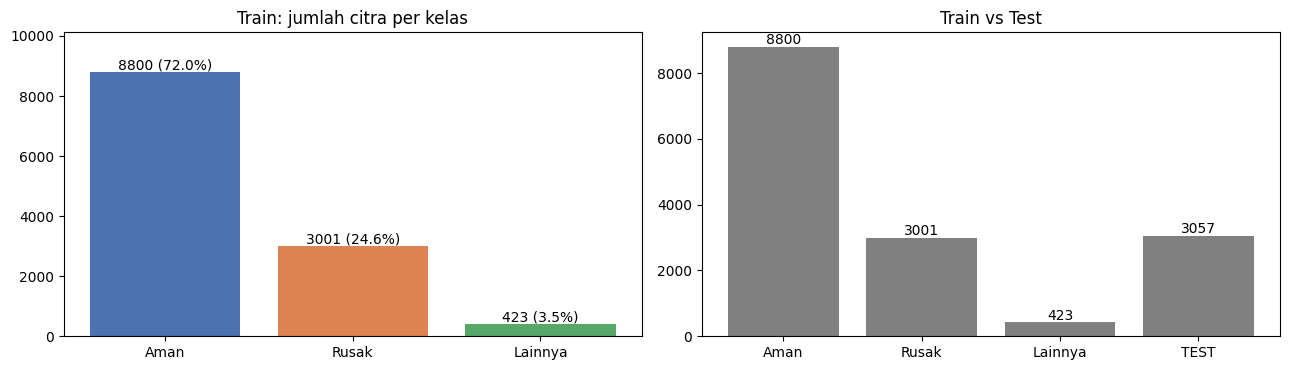

Rasio imbalance Aman:Rusak:Lainnya = [20.8, 7.1, 1.0]


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
vc = meta[meta.split == "train"].label.value_counts().reindex(CLASSES)
ax[0].bar(vc.index, vc.values, color=["#4C72B0", "#DD8452", "#55A868"])
for i, v in enumerate(vc.values): ax[0].text(i, v + 80, f"{v} ({v/vc.sum():.1%})", ha="center")
ax[0].set_title("Train: jumlah citra per kelas"); ax[0].set_ylim(0, vc.max() * 1.15)
sz = meta.groupby("grp_name").size().reindex(CLASSES + ["TEST"])
ax[1].bar(sz.index, sz.values, color="gray"); ax[1].set_title("Train vs Test")
for i, v in enumerate(sz.values): ax[1].text(i, v + 80, v, ha="center")
plt.tight_layout(); plt.show()
print("Rasio imbalance Aman:Rusak:Lainnya =", (vc / vc.min()).round(1).tolist())

### 2.2 Format file, mode warna, EXIF

In [4]:
meta["ext"] = meta.fname.str.split(".").str[-1].str.lower()
display(pd.crosstab([meta.fmt, meta.ext], meta.grp_name).rename_axis(["format asli", "ekstensi"]))
display(pd.crosstab(meta["mode"], meta.grp_name))
display(pd.crosstab(meta.exif_orient.fillna(-1).astype(int), meta.grp_name).rename_axis("EXIF orientation"))

grp_name              Aman  Lainnya  Rusak  TEST
format asli ekstensi                            
JPEG        jpeg        55        0      1    24
            jpg       7860      423   2418  2291
PNG         jpg         17        0      0    18
            png         74        0      4   127
WEBP        jpg        793        0    578   597

grp_name,Aman,Lainnya,Rusak,TEST
mode,,,,
P,6,0,1,3
RGB,8775,423,2997,2953
RGBA,18,0,3,101


grp_name,Aman,Lainnya,Rusak,TEST
EXIF orientation,,,,
-1,1,0,0,0
1,8799,422,3001,3056
6,0,1,0,1


### 2.3 Resolusi, ukuran file & sumber data
Kolom `src` ditentukan hanya dari resolusi asli citra panitia; namanya sekadar penanda kelompok.

grp_name,Aman,Rusak,Lainnya,TEST,train%,test%,test/train
src,,,,,,,
web,3384,380,75,933,31.4,30.5,0.97
n224,253,0,0,520,2.1,17.0,8.10
small_web,1121,480,318,494,15.7,16.2,1.03
rf640,1478,1305,2,347,22.8,11.4,0.50
ghtk,119,420,0,310,4.4,10.1,2.30
isocyt,87,211,0,193,2.4,6.3,2.62
ai_gen,79,0,0,123,0.6,4.0,6.67
phone,20,0,0,92,0.2,3.0,15.00
rf512,2259,205,28,45,20.4,1.5,0.07


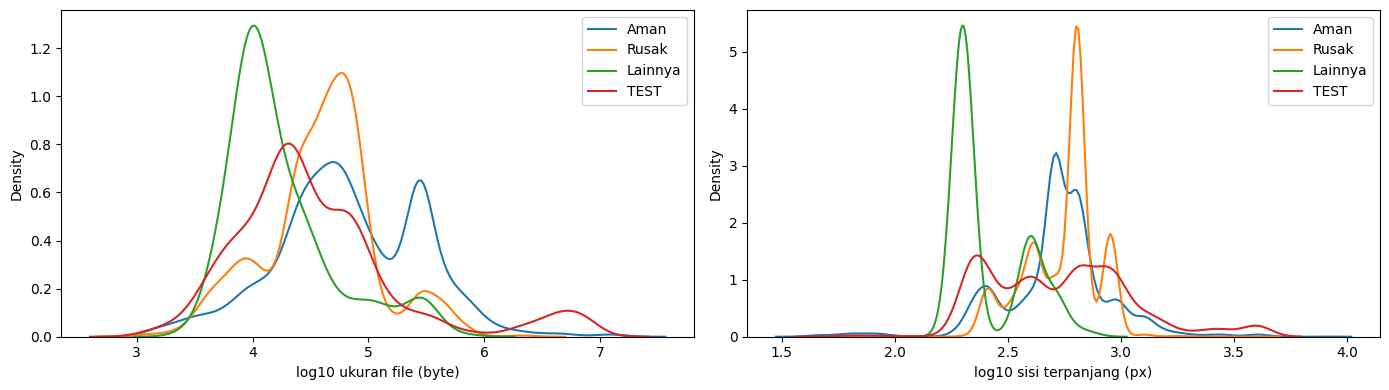

In [5]:
res = meta.w0.astype("Int64").astype(str) + "x" + meta.h0.astype("Int64").astype(str)
mp = meta.w0 * meta.h0 / 1e6
# "Keluarga sumber" = label deskriptif yang ditentukan hanya dari resolusi asli citra panitia
meta["src"] = np.select(
    [res == "640x640", res == "512x512", res == "224x224", res == "416x416", res.isin(["675x900", "679x900"]),
     res.isin(["3000x4000", "4000x3000"]), res.isin(["2816x1536", "2390x1792", "1536x1024", "1024x1024", "1248x832"]),
     (mp < 0.1) & (meta.w0 != meta.h0)],
    ["rf640", "rf512", "n224", "isocyt", "ghtk", "phone", "ai_gen", "small_web"], "web")
t = pd.crosstab(meta.src, meta.grp_name)[CLASSES + ["TEST"]]
t["train%"] = (t[CLASSES].sum(1) / (meta.split == "train").sum() * 100).round(1)
t["test%"] = (t.TEST / (meta.split == "test").sum() * 100).round(1)
t["test/train"] = (t["test%"] / t["train%"]).round(2)
display(t.sort_values("test%", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for g in CLASSES + ["TEST"]:
    sns.kdeplot(np.log10(meta.loc[meta.grp_name == g, "fsize"]), ax=ax[0], label=g)
    sns.kdeplot(np.log10(np.maximum(meta.loc[meta.grp_name == g, "w0"], meta.loc[meta.grp_name == g, "h0"]).astype(float)), ax=ax[1], label=g)
ax[0].set_xlabel("log10 ukuran file (byte)"); ax[1].set_xlabel("log10 sisi terpanjang (px)"); ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.4 Contoh citra

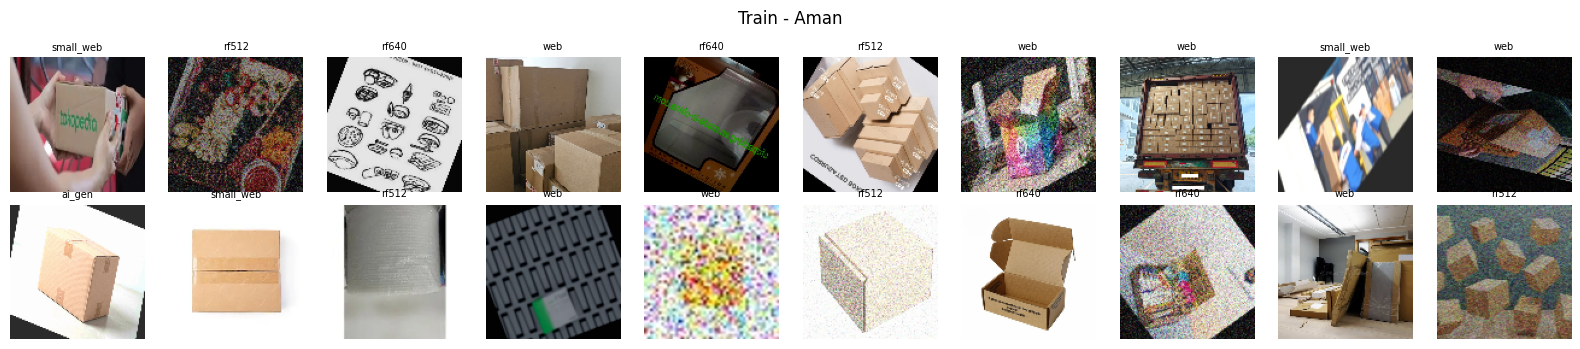

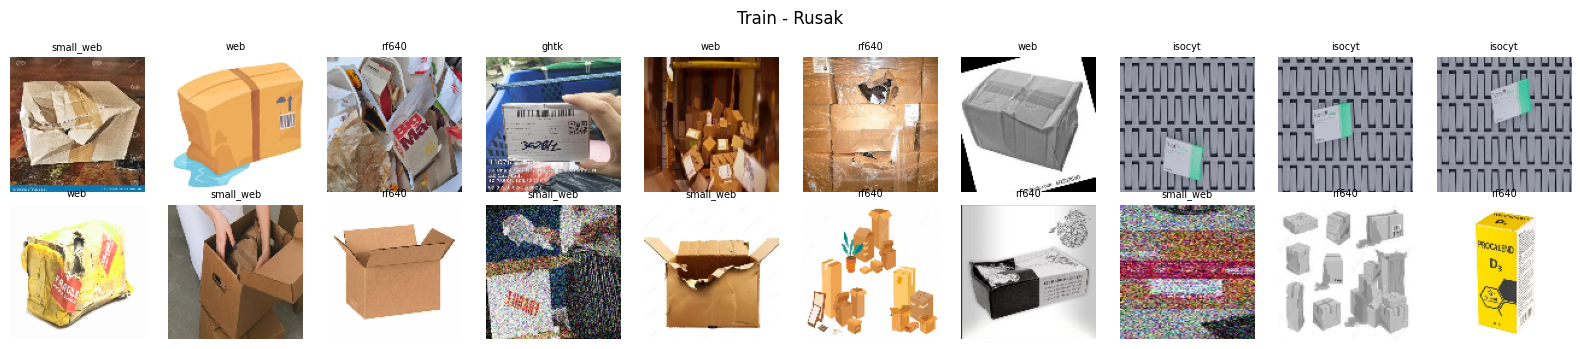

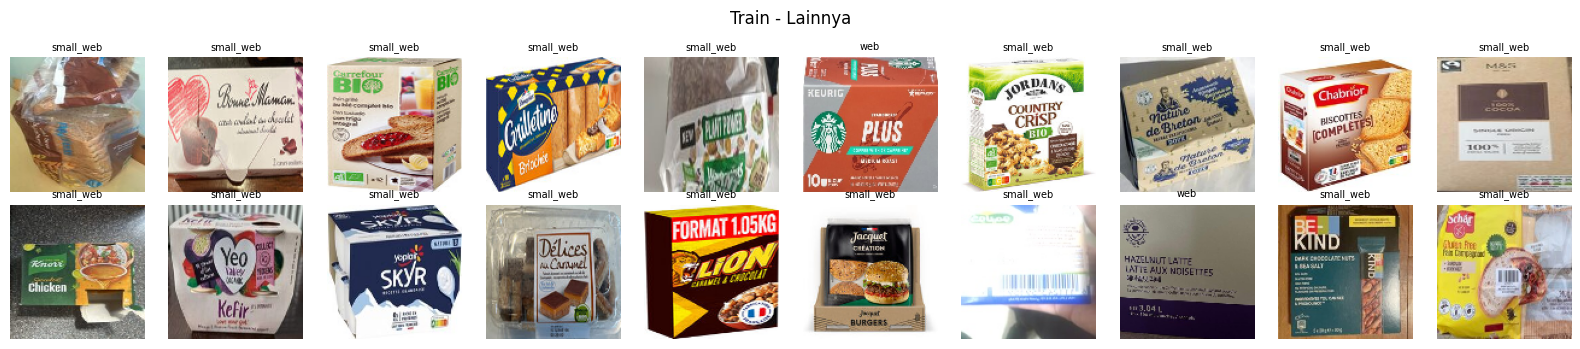

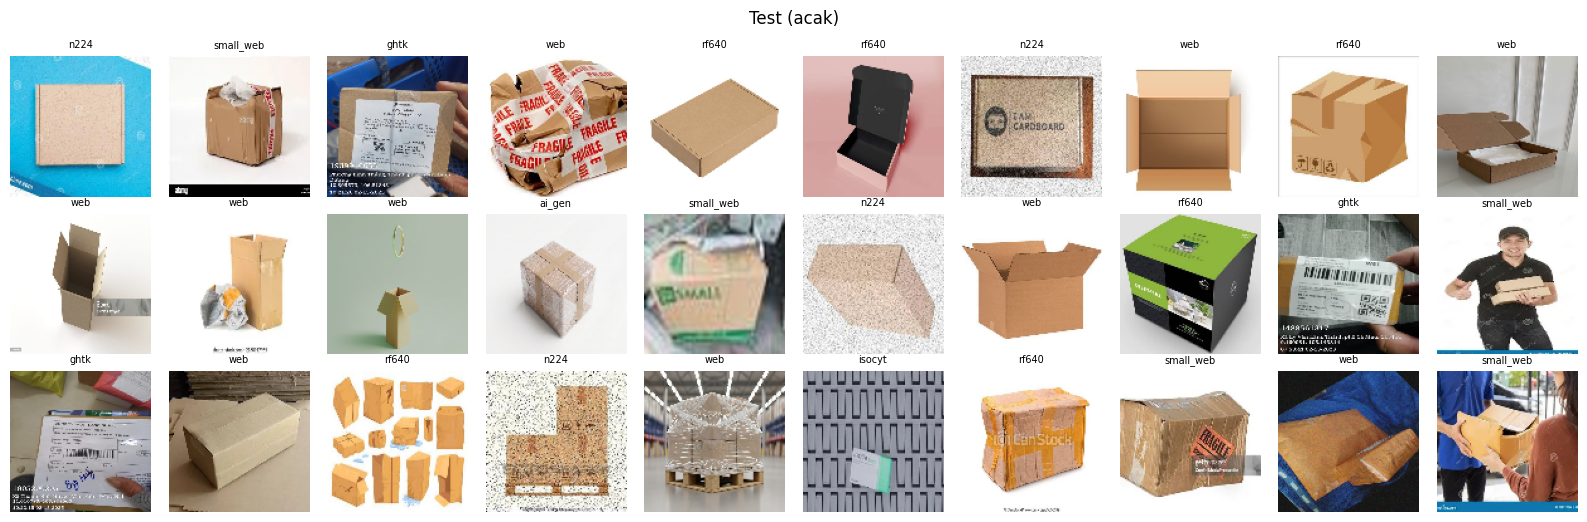

In [6]:
def show_grid(idx, titles=None, cols=10, size=1.6, suptitle=None):
    idx = list(idx); rows = (len(idx) + cols - 1) // cols
    fig, axs = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.1))
    for k, ax in enumerate(np.atleast_1d(axs).ravel()):
        ax.axis("off")
        if k < len(idx):
            ax.imshow(X448[idx[k]][::4, ::4]); ax.set_title(titles[k] if titles is not None else meta.src[idx[k]], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()
rng = np.random.default_rng(0)
for c in CLASSES:
    show_grid(rng.choice(meta.index[(meta.label == c) & meta.ok], 20, replace=False), suptitle=f"Train - {c}")
show_grid(rng.choice(meta.index[meta.split == "test"], 30, replace=False), suptitle="Test (acak)")

### 2.5 Artefak augmentasi per kelas → potensi *shortcut*

In [7]:
import cv2
def artefact_stats(i):
    x = np.asarray(X448[i]); g = cv2.cvtColor(x, cv2.COLOR_RGB2GRAY)
    medres = np.abs(g.astype(np.int16) - cv2.medianBlur(g, 3).astype(np.int16)).mean()      # residual noise (grain / salt-pepper)
    blackb = (x.max(-1) < 8).mean()                                                         # black border (rotation)
    chroma = np.abs(x[..., 0].astype(int) - x[..., 1]).mean() + np.abs(x[..., 1].astype(int) - x[..., 2]).mean()  # ~0 = grayscale
    return medres, blackb, chroma
with ThreadPoolExecutor(16) as ex: st = np.array(list(ex.map(artefact_stats, range(len(meta)))))
meta["medres"], meta["blackb"], meta["chroma"] = st[:, 0], st[:, 1], st[:, 2]
meta["noisy"] = meta.medres > 6; meta["rot_border"] = meta.blackb > 0.03; meta["gray"] = meta.chroma < 2
meta["aug"] = meta.noisy | meta.rot_border | meta.gray
display((meta[meta.ok].groupby("grp_name")[["noisy", "rot_border", "gray", "aug"]].mean() * 100).round(1).reindex(CLASSES + ["TEST"]).rename(columns=lambda c: c + " %"))
tab = meta[meta.ok].pivot_table(index="src", columns="grp_name", values="aug", aggfunc="mean").reindex(columns=CLASSES + ["TEST"])
display((tab * 100).round(0).rename(columns=lambda c: "aug% " + c))

,noisy %,rot_border %,gray %,aug %
grp_name,,,,
Aman,33.6,16.1,2.8,49.9
Rusak,10.3,11.0,7.2,27.1
Lainnya,12.1,6.6,0.2,18.7
TEST,3.8,6.7,2.4,12.6


grp_name,aug% Aman,aug% Rusak,aug% Lainnya,aug% TEST
src,,,,
ai_gen,43.0,NaN,NaN,4.0
ghtk,71.0,8.0,NaN,4.0
isocyt,55.0,6.0,NaN,0.0
n224,64.0,NaN,NaN,15.0
phone,50.0,NaN,NaN,26.0
rf512,70.0,71.0,79.0,56.0
rf640,31.0,26.0,50.0,20.0
small_web,34.0,28.0,10.0,15.0
web,48.0,38.0,33.0,10.0


## 3. Ekstraksi fitur
Embedding encoder citra dari 8 backbone pretrained yang dibekukan (bf16, TTA hflip kecuali PE-Core-G), di-*cache* ke `artifacts/emb/`.

In [8]:
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225); HALF = (0.5, 0.5, 0.5)
# key: (library, model id, input size, mean, std, batch, n_views)
BACKBONES = {
    "pe_g448":           ("timm", "vit_pe_core_gigantic_patch14_448.fb", 448, HALF, HALF, 16, 1),
    "pe_l336":           ("timm", "vit_pe_core_large_patch14_336.fb", 336, HALF, HALF, 32, 2),
    "siglip2_so400m384": ("timm", "vit_so400m_patch16_siglip_384.v2_webli", 384, HALF, HALF, 32, 2),
    "clip_h224":         ("hf",   "laion/CLIP-ViT-H-14-laion2B-s32B-b79K", 224, CLIP_MEAN, CLIP_STD, 64, 2),
    "clip_l336":         ("hf",   "openai/clip-vit-large-patch14-336", 336, CLIP_MEAN, CLIP_STD, 64, 2),
    "eva02_l_clip336":   ("timm", "eva02_large_patch14_clip_336.merged2b", 336, CLIP_MEAN, CLIP_STD, 32, 2),
    "dinov3_l448":       ("timm", "vit_large_patch16_dinov3.lvd1689m", 448, IMNET_MEAN, IMNET_STD, 32, 2),
    "dinov2_l448":       ("timm", "vit_large_patch14_reg4_dinov2.lvd142m", 448, IMNET_MEAN, IMNET_STD, 32, 2),
}

@torch.no_grad()
def extract(key):
    lib, name, size, mean, std, bs, views = BACKBONES[key]
    if lib == "timm":
        import timm
        m = timm.create_model(name, pretrained=True, num_classes=0, **({"img_size": size} if "dinov" in name else {}))
        fwd = lambda x: m(x)
    else:
        from transformers import CLIPModel
        # hanya encoder citra yang dipanggil (get_image_features)
        m = CLIPModel.from_pretrained(name, torch_dtype=torch.float16); fwd = lambda x: m.get_image_features(pixel_values=x)
    m = m.eval()
    big = sum(p.numel() for p in m.parameters()) > 1e9
    if big: m = m.to(torch.bfloat16)          # cast di CPU sebelum ke GPU: puncak VRAM/RAM model >1B (PE-Core-G) turun ±50%
    m = m.cuda()
    mean = torch.tensor(mean, device="cuda").view(1, 3, 1, 1); std = torch.tensor(std, device="cuda").view(1, 3, 1, 1)
    feats = None
    for s in range(0, len(X448), bs):
        x = torch.from_numpy(np.ascontiguousarray(X448[s:s + bs])).cuda().permute(0, 3, 1, 2).float().div_(255)
        if size != CACHE_SIZE: x = F.interpolate(x, size=(size, size), mode="bicubic", align_corners=False, antialias=True).clamp_(0, 1)
        x = (x - mean) / std
        if big: x = x.to(torch.bfloat16)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            fs = [fwd(x).float()] + ([fwd(torch.flip(x, dims=[3])).float()] if views == 2 else [])
        f = torch.stack(fs, 1).cpu().numpy().astype(np.float16)
        if feats is None: feats = np.zeros((len(X448), views, f.shape[-1]), np.float16)
        feats[s:s + len(f)] = f
    del m; gc.collect(); torch.cuda.empty_cache()
    return feats

def load_emb(key, mean_views=False):
    path = f"{ART}/emb/{key}.npy"
    if not os.path.exists(path):
        t = time.time(); np.save(path, extract(key)); print(f"  extracted {key} in {time.time()-t:.0f}s")
    E = np.load(path).astype(np.float32); E /= np.linalg.norm(E, axis=-1, keepdims=True) + 1e-8
    if mean_views: E = E.mean(1); E /= np.linalg.norm(E, axis=-1, keepdims=True) + 1e-8
    return E

EMB = {k: load_emb(k) for k in BACKBONES}
display(pd.DataFrame({k: {"views": v.shape[1], "dim": v.shape[2]} for k, v in EMB.items()}).T)

,views,dim
pe_g448,1,1536
pe_l336,2,1024
siglip2_so400m384,2,1152
clip_h224,2,1024
clip_l336,2,768
eva02_l_clip336,2,1024
dinov3_l448,2,1024
dinov2_l448,2,1024


## 4. Forensik near-duplicate
Grup salinan dari pHash/dHash D4-invariant + kNN DINOv2, diverifikasi ORB + RANSAC (`src/qc_dups.py`, cache `artifacts/dups/`). Grup STRICT dipakai untuk transfer label; grup LOOSE (lebih longgar) hanya sebagai cadangan di 7.4.

In [9]:
%%writefile src/qc_dups.py
"""Near-duplicate grouping of the image dataset (CPU only, no GPU).

Tiers returned by :func:`build_dup_groups`
  md5_group     byte-identical files.
  strict_group  same-source images: md5 + pairs verified geometrically (ORB + RANSAC homography, then an aligned
                8x8-block residual inside the overlap). Candidates come from D4-invariant pHash/dHash and DINOv2 kNN.
  loose_group   strict + pixel-level hash near-dups + heavy-overlap geometric matches with local edits
                (also merges watermark/logo edits and the synthetic-render scene siblings).
  synthetic     the synthetic 416x416 conveyor/grid render family.

Stages (each cached in `workdir`, keyed on the dataset's md5 list; delete the files to force a recompute):
  1. img_feats.npz   per image: pHash/dHash of gray and of 5x5-median-blurred gray for the 8 dihedral (D4) variants,
                     64x64 thumbnail of the median-blurred gray.
  2. hash_pairs.npz  pairs i<j with D4-min Hamming pHash<=14 or dHash<=8 (raw or blurred); pixel scores at the best
                     D4 alignment: thumbnail NCC, gradient NCC (gcc), max 8x8-block z-scored residual (bmax).
  3. hash_orb.npz    ORB/RANSAC inliers (+ aligned residual abmax / overlap when >=12 inliers) for promising hash
                     pairs: different md5 and (pHash_mb<=12 or bmax<=0.75 or gcc>=0.7); others get inl=-1.
  4. emb_orb.npz     the same verification, trying both hflip states, for DINOv2 pairs (cos>=0.88 or top-10 kNN)
                     not already ORB-checked in stage 3.
"""
import hashlib
import os
import time
from concurrent.futures import ThreadPoolExecutor
from contextlib import nullcontext

import cv2
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

try:
    from threadpoolctl import threadpool_limits
except ImportError:  # BLAS thread cap is best effort
    threadpool_limits = None

SIDE = 448                                       # side of the cached square images
_W64 = np.uint64(1) << np.arange(64, dtype=np.uint64)


# ------------------------------------------------------------------------------------------------ image primitives
def _gray_mb(X, k):
    """Grayscale and 5x5 median-blurred grayscale of cached image k."""
    gray = cv2.cvtColor(np.asarray(X[k]), cv2.COLOR_RGB2GRAY)
    return gray, cv2.medianBlur(gray, 5)


def _d4(a, axes=(0, 1)):
    """8 dihedral variants (views) of square array(s): rot0..rot270, then rot0..rot270 of the flip along axes[1]."""
    return [np.rot90(f, r, axes=axes) for f in (a, np.flip(a, axes[1])) for r in range(4)]


def _bits(b):
    """Pack <=64 booleans (row-major) into a uint64."""
    return np.uint64(np.sum(_W64[b.ravel()], dtype=np.uint64))


def _phash(g32):
    """DCT pHash of a 32x32 float image: top-left 8x8 AC coefficients > their median (DC bit forced to 0)."""
    d = cv2.dct(np.ascontiguousarray(g32))[:8, :8].ravel()
    b = d > np.median(d[1:])
    b[0] = False
    return _bits(b)


def _dhash(g):
    """Horizontal-gradient dHash of a uint8 image on a 9x8 INTER_AREA grid."""
    s = cv2.resize(np.ascontiguousarray(g), (9, 8), interpolation=cv2.INTER_AREA).astype(np.float32)
    return _bits(s[:, 1:] > s[:, :-1])


def _image_feats(X, k):
    """Hashes (4, 8) [ph_raw, ph_mb, dh_raw, dh_mb] x D4 variant, and the 64x64 uint8 median-blurred thumbnail."""
    gray, mb = _gray_mb(X, k)
    h = np.zeros((4, 8), np.uint64)
    for t, g in enumerate((gray, mb)):
        g32 = cv2.resize(g, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        h[t] = [_phash(v) for v in _d4(g32)]        # INTER_AREA x14 commutes with D4 -> transform the 32x32 grid
        h[2 + t] = [_dhash(v) for v in _d4(g)]      # dHash is direction dependent -> transform full res first
    return h, cv2.resize(mb, (64, 64), interpolation=cv2.INTER_AREA)


def _orb_feats(X, k):
    """ORB keypoints (float32 xy) and descriptors of the median-blurred gray image and of its hflip."""
    mb = _gray_mb(X, k)[1]
    orb = cv2.ORB_create(nfeatures=1000, fastThreshold=10)
    out = []
    for g in (mb, np.ascontiguousarray(mb[:, ::-1])):
        kp, ds = orb.detectAndCompute(g, None)
        out.append((np.float32([p.pt for p in kp]).reshape(-1, 2), ds))
    return out


def _match(fa, fb):
    """Ratio-test (0.8) ORB matches -> RANSAC homography (6 px). Returns (n_inliers, H); (0, None) on failure."""
    (pa, da), (pb, db) = fa, fb
    if da is None or db is None or len(da) < 8 or len(db) < 8:
        return 0, None
    mm = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(da, db, k=2)
    good = [m[0] for m in mm if len(m) == 2 and m[0].distance < 0.8 * m[1].distance]
    if len(good) < 8:
        return 0, None
    sa = pa[[m.queryIdx for m in good]]
    sb = pb[[m.trainIdx for m in good]]
    H, mask = cv2.findHomography(sa, sb, cv2.RANSAC, 6.0)
    if H is None:
        return 0, None
    return int(mask.sum()), H


def _aligned_residual(ga, gb, H):
    """Warp gb onto ga with H; z-score both inside the overlap on a 64x64 grid and return (abmax, overlap), abmax =
    max over 8x8 blocks (>=48 valid px) of mean |diff|. abmax=9 if overlap<0.15 or fewer than 4 valid blocks."""
    wb = cv2.warpPerspective(gb, H, (SIDE, SIDE), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR).astype(np.float32)
    vm = cv2.warpPerspective(np.ones_like(gb, np.float32), H, (SIDE, SIDE),
                             flags=cv2.WARP_INVERSE_MAP | cv2.INTER_NEAREST)
    A = cv2.resize(ga.astype(np.float32), (64, 64), interpolation=cv2.INTER_AREA)
    B = cv2.resize(wb, (64, 64), interpolation=cv2.INTER_AREA)
    V = cv2.resize(vm, (64, 64), interpolation=cv2.INTER_AREA) > 0.99
    ov = float(V.mean())
    if ov < 0.15:
        return 9.0, ov
    zs = lambda Z: (Z - Z[V].mean()) / (Z[V].std() + 1e-3)
    D = np.abs(zs(A) - zs(B)) * V
    bs = D.reshape(8, 8, 8, 8).sum((1, 3))
    bc = V.reshape(8, 8, 8, 8).sum((1, 3))
    ok = bc >= 48
    if ok.sum() < 4:
        return 9.0, ov
    return float((bs[ok] / bc[ok]).max()), ov


def _verify(X, bank, a, b, flips):
    """ORB-match a against b in each hflip state of `flips` (most inliers wins, ties -> first). Returns
    (inliers, abmax, overlap); the aligned residual is computed only with >=12 inliers (else abmax=9, overlap=0)."""
    best = (0, 0, None)
    for f in flips:
        n, H = _match(bank[a][0], bank[b][f])
        if n > best[0]:
            best = (n, f, H)
    n, f, H = best
    if n < 12:
        return n, 9.0, 0.0
    gb = _gray_mb(X, b)[1]
    if f:
        gb = np.ascontiguousarray(gb[:, ::-1])
    return (n, *_aligned_residual(_gray_mb(X, a)[1], gb, H))


def _orb_verify(X, bank, a, b, flips, n_jobs):
    """Run _verify over pairs (a[q], b[q], flips[q]) in parallel; returns float32 inl, abmax, overlap."""
    need = [k for k in np.unique(np.concatenate([a, b])).tolist() if k not in bank]
    with ThreadPoolExecutor(n_jobs) as ex:
        bank.update(zip(need, ex.map(lambda k: _orb_feats(X, k), need)))
        res = list(ex.map(lambda q: _verify(X, bank, int(a[q]), int(b[q]), flips[q]), range(len(a))))
    res = np.array(res, np.float32).reshape(-1, 3)
    return dict(inl=res[:, 0], abmax=res[:, 1], overlap=res[:, 2])


# ------------------------------------------------------------------------------------------------ stages
def _stage_image_feats(X, n_jobs):
    """Stage 1: per-image D4 hashes and 64x64 thumbnails."""
    N = len(X)
    H = np.zeros((N, 4, 8), np.uint64)
    T = np.zeros((N, 64, 64), np.uint8)
    with ThreadPoolExecutor(n_jobs) as ex:
        for k, (h, t) in enumerate(ex.map(lambda k: _image_feats(X, k), range(N))):
            H[k], T[k] = h, t
    return dict(hashes=H, thumbs=T)


def _popcount(x):
    """Bit count of a uint64 array (numpy>=2 ufunc, else byte lookup table)."""
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    lut = np.array([bin(v).count("1") for v in range(256)], np.uint8)
    return lut[x[..., None].view(np.uint8)].sum(-1, dtype=np.uint8)


def _hash_candidates(H, ok, n_jobs, B=256):
    """Pairs i<j (both ok) whose D4-invariant distance d(i,j) = min_v ham(h_i[id], h_j[v]) is pHash<=14 or
    dHash<=8 (raw or blurred). Returns int32 (P, 6): i, j, d_ph_raw, d_ph_mb, d_dh_raw, d_dh_mb (row-major order)."""
    N = len(H)
    Hv = [[np.ascontiguousarray(H[:, k, v]) for v in range(8)] for k in range(4)]

    def block(s):
        e = min(N, s + B)
        D = []
        for k in range(4):
            d = np.full((e - s, N), 255, np.uint8)
            q = Hv[k][0][s:e, None]
            for v in range(8):
                np.minimum(d, _popcount(q ^ Hv[k][v][None, :]), out=d)
            D.append(d)
        cand = (np.arange(N)[None, :] > np.arange(s, e)[:, None]) & ok[None, :] & ok[s:e, None]
        cand &= (D[0] <= 14) | (D[1] <= 14) | (D[2] <= 8) | (D[3] <= 8)
        ii, jj = np.nonzero(cand)
        return np.stack([ii + s, jj] + [d[ii, jj] for d in D], 1).astype(np.int32)

    with ThreadPoolExecutor(n_jobs) as ex:
        return np.concatenate(list(ex.map(block, range(0, N, B))))


def _unit_rows(A):
    """Flatten (n, ...) to rows with zero mean and unit L2 norm."""
    A = A.reshape(len(A), -1)
    A = A - A.mean(1, keepdims=True)
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-6)


def _unit_rows_d4(A):
    """(n, S, S) -> (n, 8, S*S): zero-mean unit-norm rows of every D4 variant."""
    V = np.stack(_d4(A, (1, 2)), 1).reshape(len(A), 8, -1)
    V = V - V.mean(2, keepdims=True)
    return V / (np.linalg.norm(V, axis=2, keepdims=True) + 1e-6)


def _zscore(A):
    """Per-image z-score of a batch (n, S, S)."""
    return (A - A.mean((1, 2), keepdims=True)) / (A.std((1, 2), keepdims=True) + 1e-3)


def _pixel_scores(T8, i, j, n_jobs, B=512):
    """Best D4 alignment of thumbnail j onto i by NCC (ncc, nv), gradient-magnitude NCC at that alignment (gcc),
    and bmax = max 8x8-block mean |diff| of the z-scored thumbnails at that alignment."""
    T = T8.astype(np.float32)
    G = np.zeros_like(T)
    for k in range(len(T)):
        gx, gy = cv2.Sobel(T[k], cv2.CV_32F, 1, 0), cv2.Sobel(T[k], cv2.CV_32F, 0, 1)
        G[k] = np.sqrt(gx * gx + gy * gy)
    n = len(i)
    ncc, gcc, bmax = (np.zeros(n, np.float32) for _ in range(3))
    nv = np.zeros(n, np.uint8)

    def corr(s):
        k = slice(s, s + B)
        c = np.einsum("nd,nvd->nv", _unit_rows(T[i[k]]), _unit_rows_d4(T[j[k]]))
        v = c.argmax(1)
        cg = np.einsum("nd,nvd->nv", _unit_rows(G[i[k]]), _unit_rows_d4(G[j[k]]))
        ncc[k], nv[k], gcc[k] = c.max(1), v, cg[np.arange(len(v)), v]

    def resid(job):
        v, kk = job
        d = np.abs(_zscore(T[i[kk]]) - _zscore(_d4(T[j[kk]], (1, 2))[v]))
        bmax[kk] = d.reshape(len(kk), 8, 8, 8, 8).mean((2, 4)).reshape(len(kk), 64).max(1)

    with ThreadPoolExecutor(n_jobs) as ex:
        list(ex.map(corr, range(0, n, B)))
        jobs = [(v, k[s:s + B]) for v in range(8) for k in [np.nonzero(nv == v)[0]] for s in range(0, len(k), B)]
        list(ex.map(resid, jobs))
    return dict(ncc=ncc, gcc=gcc, nv=nv, bmax=bmax)


def _emb_candidates(E, ok, md5, done, K=20, B=1024):
    """DINOv2 cosine pairs: cos>=0.88 (cos truncated to 1e-4 as in the original) or j in the top-10 kNN of i
    (ordered from an argpartition top-20). Drops self/same-md5/non-ok pairs and pair keys in `done`.
    Note: the float32 GEMM's last bits depend on the BLAS build/thread count, which can swap which of several
    md5-identical images (identical embeddings) fills a top-10 slot; groups are unaffected (md5 copies merge anyway)."""
    N = len(E)
    A, Bj = [], []
    for s in range(0, N, B):
        rows = np.arange(s, min(N, s + B))
        S = E[s:s + B] @ E.T
        S[np.arange(len(rows)), rows] = -1
        S[:, ~ok] = -1
        idx = np.argpartition(-S, K, axis=1)[:, :K]
        top = np.take_along_axis(idx, np.argsort(-np.take_along_axis(S, idx, 1), 1), 1)[:, :10]
        ii, jj = np.nonzero((np.arange(N)[None, :] > rows[:, None]) & (S >= 0.87))  # prefilter, exact test next
        hit = ((S[ii, jj] * 1e4).astype(np.int64) / 1e4).astype(np.float32) >= 0.88
        A += [np.repeat(rows, 10), ii[hit] + s]
        Bj += [top.ravel(), jj[hit]]
    A, Bj = np.concatenate(A), np.concatenate(Bj)
    a, b = np.minimum(A, Bj), np.maximum(A, Bj)
    key, u = np.unique(a.astype(np.int64) * N + b, return_index=True)
    a, b = a[u], b[u]
    keep = ~np.isin(key, done) & (a != b) & (md5[a] != md5[b]) & ok[a] & ok[b]
    return a[keep], b[keep]


def _components(N, edges):
    """Connected-component labels numbered by each component's smallest member (as a min-root union-find)."""
    g = coo_matrix((np.ones(len(edges), np.int8), (edges[:, 0], edges[:, 1])), shape=(N, N))
    lab = connected_components(g, directed=False)[1]
    first = np.unique(lab, return_index=True)[1]
    rank = np.empty(len(first), np.int64)
    rank[np.argsort(first)] = np.arange(len(first))
    return rank[lab]


def _cached(path, key, fn, log):
    """Load the arrays saved at `path` for dataset `key`, or compute fn() -> dict of arrays and save it atomically."""
    if os.path.exists(path):
        with np.load(path) as z:
            if str(z["_key"]) == key:
                log(f"  cached {os.path.basename(path)}")
                return {k: z[k] for k in z.files if k != "_key"}
    t = time.time()
    out = fn()
    with open(path + ".tmp", "wb") as f:
        np.savez(f, _key=key, **out)
    os.replace(path + ".tmp", path)
    log(f"  computed {os.path.basename(path)} in {time.time() - t:.0f}s")
    return out


# ------------------------------------------------------------------------------------------------ entry point
def build_dup_groups(meta: pd.DataFrame, cache_path: str, dino_emb_path: str, workdir: str,
                     n_jobs: int = 8, verbose=True) -> pd.DataFrame:
    """Near-duplicate groups for the images of `meta` (rows aligned with the uint8 (N,448,448,3) cache at
    `cache_path` and the DINOv2 embeddings (N,[views,]D) at `dino_emb_path`; uses meta columns md5, ok, w, h).

    Returns one row per image: idx, md5_group, strict_group, loose_group (-1 for rows with ok=False), synthetic.
    Intermediate arrays are cached in `workdir`. Uses at most `n_jobs` threads (OpenCV, numpy BLAS) and no GPU."""
    log = print if verbose else (lambda *a, **k: None)
    t0 = time.time()
    os.makedirs(workdir, exist_ok=True)
    X = np.load(cache_path, mmap_mode="r")
    N = len(meta)
    assert len(X) == N and X.shape[1:] == (SIDE, SIDE, 3), (X.shape, N)
    md5 = meta["md5"].astype(str).values
    ok = meta["ok"].astype(bool).values if "ok" in meta else np.ones(N, bool)
    w416 = ((meta["w"] == 416) & (meta["h"] == 416)).values
    key = hashlib.md5(("\n".join(md5) + f"|{N}").encode()).hexdigest()
    wp = lambda name: os.path.join(workdir, name)
    bank = {}  # ORB features shared by stages 3 and 4

    prev_cv = cv2.getNumThreads()
    cv2.setNumThreads(1)  # parallelism comes from our own thread pools
    try:
        with threadpool_limits(n_jobs) if threadpool_limits else nullcontext():
            log("[1/4] hashes + thumbnails")
            imf = _cached(wp("img_feats.npz"), key, lambda: _stage_image_feats(X, n_jobs), log)

            log("[2/4] hash candidates + pixel scores")
            def stage2():
                P = _hash_candidates(imf["hashes"], ok, n_jobs)
                return dict(pairs=P, **_pixel_scores(imf["thumbs"], P[:, 0], P[:, 1], n_jobs))
            hp = _cached(wp("hash_pairs.npz"), key, stage2, log)
            i, j, phr, phm, dhr, dhm = hp["pairs"].T

            log("[3/4] ORB verification of hash candidates")
            def stage3():
                sel = np.nonzero((md5[i] != md5[j]) & ((phm <= 12) | (hp["bmax"] <= 0.75) | (hp["gcc"] >= 0.7)))[0]
                r = _orb_verify(X, bank, i[sel], j[sel], [(int(v >= 4),) for v in hp["nv"][sel]], n_jobs)
                out = dict(inl=np.full(len(i), -1, np.float32), abmax=np.full(len(i), 9, np.float32),
                           overlap=np.zeros(len(i), np.float32))
                for k in out:
                    out[k][sel] = r[k]
                return out
            ho = _cached(wp("hash_orb.npz"), key, stage3, log)

            log("[4/4] DINOv2 kNN candidates + ORB verification")
            def stage4():
                E = np.load(dino_emb_path).astype(np.float32)
                if E.ndim == 3:
                    E = E.mean(1)  # average of the views (orig / hflip)
                E /= np.linalg.norm(E, axis=1, keepdims=True) + 1e-6
                tried = (ho["inl"] >= 0) | (md5[i] == md5[j])
                a, b = _emb_candidates(E, ok, md5, i[tried].astype(np.int64) * N + j[tried])
                log(f"  {len(a)} embedding pairs to verify")
                return dict(i=a, j=b, **_orb_verify(X, bank, a, b, [(0, 1)] * len(a), n_jobs))
            ep = _cached(wp("emb_orb.npz"), key, stage4, log)
    finally:
        cv2.setNumThreads(prev_cv)
    del bank

    # synthetic render family: every 416x416 image, plus any image with >=2 strong ORB matches (>=100 inliers,
    # overlap>=0.5) to 416x416 images (re-exports of the same renders at other sizes)
    routes = [(i, j, ho["inl"], ho["abmax"], ho["overlap"]), (ep["i"], ep["j"], ep["inl"], ep["abmax"], ep["overlap"])]
    strong = np.concatenate([np.stack([a[(n >= 100) & (ov >= 0.5)], b[(n >= 100) & (ov >= 0.5)]], 1)
                             for a, b, n, _, ov in routes])
    cnt416 = (np.bincount(strong[:, 0][w416[strong[:, 1]]], minlength=N)
              + np.bincount(strong[:, 1][w416[strong[:, 0]]], minlength=N))
    syn = w416 | (cnt416 >= 2)

    def geo(a, b, n, ab, ov):
        """STRICT edge rule; renders share an identical background, so edges touching them need abmax<=0.30."""
        base = (ov >= 0.3) & (((n >= 15) & (ab <= 0.40)) | ((n >= 60) & (ab <= 0.55)))
        return np.where(syn[a] | syn[b], (ov >= 0.3) & (n >= 15) & (ab <= 0.30), base)

    def edit(a, b, n, ab, ov):
        """LOOSE extra rule: heavy-overlap geometric match with local edits."""
        return (n >= 100) & (ov >= 0.5) & (ab <= 1.2)

    pick = lambda r, m: np.stack([r[0][m], r[1][m]], 1)
    strict_e = np.concatenate([pick(r, geo(*r)) for r in routes])
    pix = (phm <= 6) & (dhm <= 8) & (hp["bmax"] <= 0.5)
    loose_e = np.concatenate([strict_e, pick(routes[0], pix)] + [pick(r, edit(*r)) for r in routes])

    md5_group = pd.factorize(md5)[0]
    first = np.unique(md5_group, return_index=True, return_inverse=True)
    md5_e = np.stack([first[1][first[2]], np.arange(N)], 1)  # each image -> first image with the same md5
    out = pd.DataFrame(dict(idx=np.arange(N), md5_group=md5_group))
    for name, e in (("strict_group", strict_e), ("loose_group", loose_e)):
        e = e[ok[e[:, 0]] & ok[e[:, 1]]].astype(np.int64)
        out[name] = np.where(ok, _components(N, np.concatenate([md5_e, e])), -1)
    out["synthetic"] = syn
    log(f"done in {time.time() - t0:.0f}s: {out.strict_group[ok].nunique()} strict / {out.loose_group[ok].nunique()} "
        f"loose groups, {int(syn.sum())} synthetic")
    return out

Overwriting src/qc_dups.py


In [10]:
sys.path.insert(0, f"{ROOT}/src")
import importlib, qc_dups; importlib.reload(qc_dups)
t0 = time.time()
dups = qc_dups.build_dup_groups(meta, f"{ART}/cache{CACHE_SIZE}.npy", f"{ART}/emb/dinov2_l448.npy", f"{ART}/dups", n_jobs=8)
meta["md5_group"], meta["strict"], meta["synthetic"] = dups.md5_group.values, dups.strict_group.values, dups.synthetic.values
print(f"{time.time()-t0:.1f}s")

[1/4] hashes + thumbnails
  cached img_feats.npz
[2/4] hash candidates + pixel scores
  cached hash_pairs.npz
[3/4] ORB verification of hash candidates
  cached hash_orb.npz


[4/4] DINOv2 kNN candidates + ORB verification
  cached emb_orb.npz
done in 0s: 8137 strict / 7211 loose groups, 534 synthetic
0.2s


### 4.1 Grup CV dan fold
Grup CV = gabungan MD5 identik, grup STRICT, dan kemiripan DINOv2 ≥ 0,95; fold dari `StratifiedGroupKFold(5)`.

In [11]:
N = len(meta); OK = meta.ok.values
par = np.arange(N)
def find(a):
    while par[a] != a: par[a] = par[par[a]]; a = par[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: par[max(ra, rb)] = min(ra, rb)
for col in ["md5", "strict"]:
    for _, g in meta[meta.ok].groupby(col):
        ii = g.index.values
        for j in ii[1:]: union(ii[0], j)
# top-10 tetangga DINOv2 (tanpa diri sendiri)
E = torch.from_numpy(load_emb("dinov2_l448", mean_views=True)); E[~torch.from_numpy(OK)] = 0
sims = np.zeros((N, 10), np.float32); nbrs = np.zeros((N, 10), np.int64)
for s in range(0, N, 2048):
    S = E[s:s + 2048] @ E.T; S[torch.arange(S.shape[0]), torch.arange(s, s + S.shape[0])] = -1
    v, i = S.topk(10, dim=1); sims[s:s + 2048] = v.numpy(); nbrs[s:s + 2048] = i.numpy()
for i in np.where(OK)[0]:
    for sv, j in zip(sims[i], nbrs[i]):
        if sv >= 0.95 and OK[j]: union(i, j)
meta["grp"] = [find(i) for i in range(N)]
tr_all = meta[(meta.split == "train") & meta.ok]
fold = np.full(len(tr_all), -1)
for f, (_, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tr_all, tr_all.y, tr_all.grp)): fold[va] = f
g2f = dict(zip(tr_all.grp, fold))
meta["fold"] = [g2f.get(g, -1) for g in meta.grp]; meta.loc[tr_all.index, "fold"] = fold   # test ikut fold grupnya
sz = tr_all.groupby("grp").size()
print(f"grup train: {len(sz)} (singleton {int((sz==1).sum())}, terbesar {sz.max()}) | test yang terhubung ke train: {meta[(meta.split=='test')].grp.isin(tr_all.grp).sum()}")
display(pd.crosstab(meta.loc[tr_all.index, "fold"], tr_all.label)[CLASSES])

grup train: 6432 (singleton 3886, terbesar 161) | test yang terhubung ke train: 2114


label,Aman,Rusak,Lainnya
fold,,,
0,1667,688,81
1,1814,654,82
2,1853,568,90
3,1656,547,87
4,1809,544,83


### 4.2 Transfer label salinan (leave-one-out pada train)

In [12]:
def loo_counts(col):
    trm = meta[(meta.split == "train") & meta.ok]
    G = trm.groupby(col).y.apply(lambda s: np.bincount(s, minlength=3)).to_dict()
    cnt = np.zeros((N, 3))
    for i in np.where(OK)[0]:
        c = G.get(meta.at[i, col])
        if c is None: continue
        c = c.copy()
        if meta.at[i, "split"] == "train": c[meta.at[i, "y"]] -= 1      # leave-one-out
        cnt[i] = c
    return cnt
CNT = loo_counts("strict")
meta["has_mate"] = CNT.sum(1) > 0
meta["una"] = meta.has_mate & ((CNT > 0).sum(1) == 1)
meta["leak_y"] = np.where(meta.has_mate, CNT.argmax(1), -1)
trmask = (meta.split == "train").values & OK; temask = (meta.split == "test").values
ok_pred = meta.leak_y.values == meta.y.values
print(f"TRAIN punya salinan: {(meta.has_mate & trmask).sum()} | akurasi transfer LOO = {ok_pred[meta.has_mate & trmask].mean():.4f} "
      f"(grup seragam: {ok_pred[meta.una & trmask].mean():.4f})")
print(f"TEST punya salinan berlabel di train: {(meta.has_mate & temask).sum()} / {temask.sum()} (seragam: {(meta.una & temask).sum()})")
d = meta[trmask & meta.has_mate.values]
a = pd.DataFrame({"train_n": d.groupby("src").size(), "akurasi_LOO": pd.Series(ok_pred[trmask & meta.has_mate.values]).groupby(d.src.values).mean().round(3)})
te_ = meta[temask]
a["test_n"] = te_.groupby("src").size(); a["test_matched"] = te_[te_.has_mate].groupby("src").size()
lt = pd.crosstab(te_[te_.has_mate].src, np.array(CLASSES)[te_[te_.has_mate].leak_y.values]).reindex(columns=CLASSES, fill_value=0)
a = a.join(lt.add_prefix("transfer_")).fillna(0).astype({"train_n": int, "test_n": int, "test_matched": int})
display(a)

TRAIN punya salinan: 7801 | akurasi transfer LOO = 0.9722 (grup seragam: 0.9854)
TEST punya salinan berlabel di train: 1831 / 3057 (seragam: 1725)


,train_n,akurasi_LOO,test_n,test_matched,transfer_Aman,transfer_Rusak,transfer_Lainnya
ai_gen,49,1.000,123,73,73,0,0
ghtk,152,1.000,310,187,187,0,0
isocyt,53,0.925,193,57,47,10,0
n224,111,1.000,520,276,276,0,0
phone,8,1.000,92,44,44,0,0
rf512,1519,0.984,45,33,26,7,0
rf640,2534,0.970,347,301,88,213,0
small_web,922,0.945,494,267,109,157,1
web,2453,0.975,933,593,521,72,0


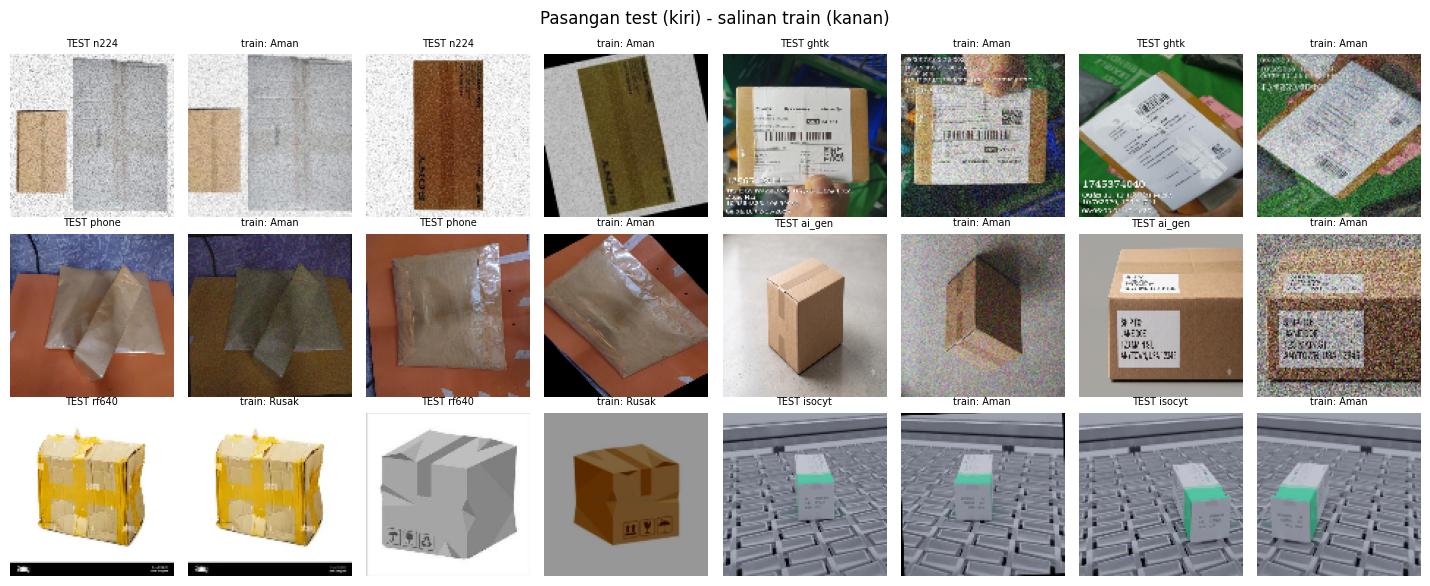

In [13]:
# contoh pasangan test <-> salinan train berlabel
pairs = []
for s in ["n224", "ghtk", "phone", "ai_gen", "rf640", "isocyt"]:
    tt = te_[(te_.src == s) & te_.una]
    for ti in rng.choice(tt.index, min(2, len(tt)), replace=False):
        mate = meta.index[(meta.strict == meta.strict[ti]) & trmask][0]
        pairs += [(ti, f"TEST {s}"), (mate, f"train: {meta.label[mate]}")]
show_grid([p[0] for p in pairs], [p[1] for p in pairs], cols=8, size=1.8, suptitle="Pasangan test (kiri) - salinan train (kanan)")

## 5. Modelling
Group CV 5-fold. Citra test yang punya salinan train berlabel seragam diberi pseudo-label otomatis (label salinannya) dan dipakai sebagai *anchor* latih (bobot 0,7, fold-aware). Head: Logistic Regression dan MLP dengan *class weight* ∝ n_c^-0,5.

In [14]:
def balanced_cw(y, pw=0.5):
    c = np.bincount(y, minlength=3); return (len(y) / (len(c) * c)) ** pw

def fit_lr(X, y, w, cw, Xte, wd=1e-3, iters=200):
    X = torch.as_tensor(X, device=DEVICE); y = torch.as_tensor(y, device=DEVICE).long()
    mu, sd = X.mean(0, keepdim=True), X.std(0, keepdim=True) + 1e-6; Xs = (X - mu) / sd
    W = torch.zeros(X.shape[1], 3, device=DEVICE, requires_grad=True); b = torch.zeros(3, device=DEVICE, requires_grad=True)
    sw = torch.as_tensor(w, device=DEVICE, dtype=torch.float32) * torch.as_tensor(cw, device=DEVICE, dtype=torch.float32)[y]; sw = sw / sw.sum()
    opt = torch.optim.LBFGS([W, b], lr=1, max_iter=iters, history_size=20, line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad(); loss = (F.cross_entropy(Xs @ W + b, y, reduction="none") * sw).sum() + wd * (W ** 2).sum(); loss.backward(); return loss
    opt.step(closure)
    with torch.no_grad(): return (((torch.as_tensor(Xte, device=DEVICE) - mu) / sd) @ W + b).softmax(1).cpu().numpy()

def fit_mlp(X, y, w, cw, Xte, wd=1e-2, hidden=1024, drop=0.5, epochs=40, lr=1e-3, ls=0.1, noise=0.02, bs=256, seed=0):
    torch.manual_seed(seed)
    X = torch.as_tensor(X, device=DEVICE); y = torch.as_tensor(y, device=DEVICE).long()
    mu, sd = X.mean(0, keepdim=True), X.std(0, keepdim=True) + 1e-6; Xs = (X - mu) / sd
    sw = torch.as_tensor(w, device=DEVICE, dtype=torch.float32) * torch.as_tensor(cw, device=DEVICE, dtype=torch.float32)[y]
    net = nn.Sequential(nn.Dropout(0.2), nn.Linear(X.shape[1], hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, 3)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd); n = len(X)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * ((n + bs - 1) // bs), pct_start=0.1)
    for ep in range(epochs):
        perm = torch.randperm(n, device=DEVICE)
        for s in range(0, n, bs):
            ii = perm[s:s + bs]; xb = Xs[ii] + noise * torch.randn_like(Xs[ii]) * sd.mean()
            loss = (F.cross_entropy(net(xb), y[ii], reduction="none", label_smoothing=ls) * sw[ii]).sum() / sw[ii].sum()
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    net.eval()
    with torch.no_grad(): return net(((torch.as_tensor(Xte, device=DEVICE) - mu) / sd)).softmax(1).cpu().numpy()

TR = meta[(meta.split == "train") & meta.ok]; TE = meta[meta.split == "test"]

def run_heads(keys, head="lr", wd=1e-2, anchor=True, cw_pow=0.5, seeds=3):
    Es = [EMB[k] for k in keys]; V = max(E.shape[1] for E in Es)
    X = np.concatenate([E if E.shape[1] == V else np.repeat(E, V, axis=1) for E in Es], -1)   # (N, V, D)
    anc = TE[TE.una & (TE.fold >= 0)] if anchor else TE.iloc[:0]
    oof = np.zeros((N, 3), np.float32); tef = np.zeros((5, N, 3), np.float32)
    for f in range(5):
        trn = pd.concat([TR[TR.fold != f], anc[anc.fold != f]])            # anchor fold-aware
        ytr = np.where(trn.split == "train", trn.y, trn.leak_y).astype(int)
        w = np.where(trn.split == "test", 0.7, 1.0)
        Xtr = np.concatenate([X[trn.index, v] for v in range(V)]); ytrv = np.tile(ytr, V); wv = np.tile(w, V)
        pidx = np.concatenate([TR.index[TR.fold == f], TE.index]); Xp = np.concatenate([X[pidx, v] for v in range(V)])
        cw = balanced_cw(ytr, cw_pow)
        if head == "lr": P = fit_lr(Xtr, ytrv, wv, cw, Xp, wd=wd)
        else: P = np.mean([fit_mlp(Xtr, ytrv, wv, cw, Xp, wd=wd, seed=s) for s in range(seeds)], 0)
        P = P.reshape(V, len(pidx), 3).mean(0); nv = (TR.fold == f).sum()
        oof[pidx[:nv]] = P[:nv]; tef[f, pidx[nv:]] = P[nv:]
    return oof, tef

def evaluate(oof, tef, name):
    y = TR.y.values; p = oof[TR.index].argmax(1); sg = ~TR.has_mate.values
    tp = TE[TE.una & (TE.fold >= 0)]; ptp = tef[tp.fold.values, tp.index].argmax(1)
    r = dict(model=name, oof_macroF1=macro_f1(y, p), oof_singleton=macro_f1(y[sg], p[sg]),
             f1_Aman=f1_score(y, p, average=None)[0], f1_Rusak=f1_score(y, p, average=None)[1], f1_Lainnya=f1_score(y, p, average=None)[2],
             tproxy_acc=(ptp == tp.leak_y.values).mean(), tproxy_ghtk=(ptp == tp.leak_y.values)[tp.src.values == "ghtk"].mean(),
             test_pred=np.bincount(tef.mean(0)[TE.index].argmax(1), minlength=3).tolist())
    return r

### 5.1 Perbandingan backbone (LR, tanpa anchor)
`oof_singleton` = OOF pada train tanpa salinan; `tproxy_*` = akurasi out-of-fold pada citra *anchor* test terhadap label salinannya.

In [15]:
t0 = time.time(); rows = []
for k in BACKBONES:
    o, t = run_heads([k], head="lr", wd=1e-2, anchor=False); rows.append(evaluate(o, t, k))
cmp_bb = pd.DataFrame(rows).set_index("model").round(4).sort_values("oof_macroF1", ascending=False)
display(cmp_bb); print(f"{time.time()-t0:.0f}s")

,oof_macroF1,oof_singleton,f1_Aman,f1_Rusak,f1_Lainnya,tproxy_acc,tproxy_ghtk,test_pred
model,,,,,,,,
pe_l336,0.8701,0.8896,0.9185,0.7618,0.9298,0.8359,0.0642,"[1727, 1275, 55]"
pe_g448,0.8676,0.8860,0.9125,0.7436,0.9467,0.8348,0.0749,"[1716, 1286, 55]"
siglip2_so400m384,0.8590,0.8722,0.9083,0.7280,0.9406,0.8371,0.0695,"[1715, 1287, 55]"
eva02_l_clip336,0.8434,0.8740,0.9033,0.7086,0.9183,0.8133,0.0214,"[1698, 1304, 55]"
clip_l336,0.8432,0.8669,0.9001,0.7017,0.9278,0.8284,0.0802,"[1710, 1291, 56]"
clip_h224,0.8414,0.8656,0.9006,0.7035,0.9200,0.8388,0.0428,"[1701, 1301, 55]"
dinov3_l448,0.8270,0.8626,0.8946,0.6905,0.8958,0.8157,0.1123,"[1686, 1316, 55]"
dinov2_l448,0.7840,0.8551,0.8831,0.6671,0.8018,0.8319,0.2620,"[1758, 1244, 55]"


32s


### 5.2 Head LR & MLP: konkatenasi 8 backbone + anchor
Dilatih ulang dengan bobot Confident Learning di 5.4.

In [16]:
KEYS = list(BACKBONES)
t0 = time.time()
oof_lr, tef_lr = run_heads(KEYS, head="lr", wd=0.03, anchor=True)
oof_mlp, tef_mlp = run_heads(KEYS, head="mlp", wd=0.05, anchor=True)
res = pd.DataFrame([evaluate(oof_lr, tef_lr, "concat8 LR + anchor"), evaluate(oof_mlp, tef_mlp, "concat8 MLP + anchor")]).set_index("model").round(4)
display(res); print(f"{time.time()-t0:.0f}s")
np.save(f"{ART}/nb_oof_lr.npy", oof_lr); np.save(f"{ART}/nb_tef_lr.npy", tef_lr); np.save(f"{ART}/nb_oof_mlp.npy", oof_mlp); np.save(f"{ART}/nb_tef_mlp.npy", tef_mlp)

,oof_macroF1,oof_singleton,f1_Aman,f1_Rusak,f1_Lainnya,tproxy_acc,tproxy_ghtk,test_pred
model,,,,,,,,
concat8 LR + anchor,0.8809,0.8986,0.9243,0.7663,0.9520,0.8922,0.3904,"[1962, 1040, 55]"
concat8 MLP + anchor,0.8826,0.8921,0.9279,0.7603,0.9594,0.9299,0.5561,"[2129, 873, 55]"


205s


### 5.3 Fine-tuning ConvNeXt-B
ConvNeXt-B (ImageNet-22k) 288 px, 12 epoch, fold + *anchor* sama dengan 5.2; dijalankan sebagai subprocess, cache `artifacts/ft/`. Hasilnya dipakai untuk Confident Learning (5.4).

In [17]:
%%writefile src/qc_ft.py
"""Fine-tuning ConvNeXt-B (ImageNet-22k) untuk dipakai sebagai head ketiga ensemble.
Data dibaca dari cache memmap (N,448,448,3) uint8 notebook. Dipanggil lewat src/run_ft.py (subprocess),
karena DataLoader multi-worker di Windows tidak bisa memakai kelas yang didefinisikan di dalam notebook."""
import math, time, numpy as np, torch, timm, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class RandomDownscale:
    """Turunkan resolusi lalu naikkan lagi: mencegah shortcut 'citra kecil = Lainnya'."""
    def __init__(self, p=0.25, lo=48, hi=200): self.p, self.lo, self.hi = p, lo, hi
    def __call__(self, im):
        if np.random.rand() < self.p:
            s = np.random.randint(self.lo, self.hi); r = s / max(im.size)
            if r < 1: im = im.resize((max(1, int(im.size[0] * r)), max(1, int(im.size[1] * r))), Image.BILINEAR)
        return im


class GaussNoise:
    def __init__(self, p=0.2, sigma=(0.02, 0.15)): self.p, self.sigma = p, sigma
    def __call__(self, x):
        if np.random.rand() < self.p: x = (x + torch.randn_like(x) * np.random.uniform(*self.sigma)).clamp(0, 1)
        return x


def build_tf(size, train):
    if train:
        return T.Compose([RandomDownscale(), T.RandomResizedCrop(size, scale=(0.35, 1.0), ratio=(0.6, 1.66), antialias=True),
                          T.RandomHorizontalFlip(), T.RandomApply([T.RandomRotation(30)], p=0.3),
                          T.RandomApply([T.ColorJitter(0.3, 0.3, 0.3, 0.05)], p=0.6), T.RandomGrayscale(0.1),
                          T.ToImage(), T.ToDtype(torch.float32, scale=True), GaussNoise(), T.Normalize(MEAN, STD)])
    return T.Compose([T.Resize((size, size), antialias=True), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])


class MemDS(Dataset):
    def __init__(self, cache_path, idx, labels, tf): self.cache_path, self.idx, self.labels, self.tf, self.X = cache_path, np.asarray(idx), labels, tf, None
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        if self.X is None: self.X = np.load(self.cache_path, mmap_mode="r")
        x = self.tf(Image.fromarray(np.asarray(self.X[self.idx[i]])))
        return x, (-1 if self.labels is None else int(self.labels[i]))


@torch.no_grad()
def predict(model, cache_path, idx, size, bs=64, workers=8):
    model.eval(); out = []
    for x, _ in DataLoader(MemDS(cache_path, idx, None, build_tf(size, False)), batch_size=bs, num_workers=workers):
        x = x.cuda(non_blocking=True).to(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            p = model(x).float().softmax(1) + model(x.flip(3)).float().softmax(1)      # TTA hflip
        out.append((p / 2).cpu())
    return torch.cat(out).numpy()


def train(cache_path, idx, y, size=288, epochs=12, bs=32, lr=1e-4, wd=0.05, smoothing=0.1, seed=0, workers=8, log=print,
          name="convnext_base.fb_in22k_ft_in1k_384"):
    torch.manual_seed(seed); np.random.seed(seed)
    model = timm.create_model(name, pretrained=True, num_classes=3, drop_path_rate=0.2).cuda().to(memory_format=torch.channels_last)
    cnt = np.bincount(y, minlength=3); cw = torch.tensor((cnt.sum() / cnt) ** 0.5, dtype=torch.float32); cw = (cw / cw.mean()).cuda()
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=smoothing)
    dl = DataLoader(MemDS(cache_path, idx, y, build_tf(size, True)), batch_size=bs, shuffle=True, drop_last=True,
                    num_workers=workers, pin_memory=True, persistent_workers=True)
    head = set(id(p) for p in model.get_classifier().parameters())
    opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head], "lr": lr},
                             {"params": [p for p in model.parameters() if id(p) in head], "lr": lr * 10}], weight_decay=wd)
    total, warm = epochs * len(dl), len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1, s / total))))
    for ep in range(epochs):
        model.train(); t = time.time(); tot = 0
        for x, yb in dl:
            x = x.cuda(non_blocking=True).to(memory_format=torch.channels_last); yb = yb.cuda(non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16): logits = model(x).float()
            loss = crit(logits, yb); opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); tot += loss.item()
        log(f"ep{ep + 1}/{epochs} loss={tot / len(dl):.4f} {time.time() - t:.0f}s")
    return model

Overwriting src/qc_ft.py


In [18]:
%%writefile src/run_ft.py
"""5-fold fine-tuning dengan fold notebook + anchor test fold-aware. usage: python src/run_ft.py ART SIZE EPOCHS"""
import os, sys, numpy as np, pandas as pd, torch
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import qc_ft

if __name__ == "__main__":
    ART, size, epochs = sys.argv[1], int(sys.argv[2]), int(sys.argv[3])
    torch.backends.cudnn.benchmark = True
    m = pd.read_csv(f"{ART}/ft_folds.csv"); cache = f"{ART}/cache448.npy"
    TR = m[(m.split == "train") & m.ok]; TE = m[m.split == "test"]; anc = TE[TE.una & (TE.fold >= 0)]
    for f in range(5):
        out = f"{ART}/ft/convnext_anchor_{size}_f{f}.npz"
        if os.path.exists(out): print(f"[fold{f}] cache ada, dilewati", flush=True); continue
        trn = pd.concat([TR[TR.fold != f], anc[anc.fold != f]])                    # anchor fold-aware
        ytr = np.where(trn.split == "train", trn.y, trn.leak_y).astype(int)
        va = TR[TR.fold == f]
        model = qc_ft.train(cache, trn.idx.values, ytr, size=size, epochs=epochs, seed=f, log=lambda s: print(f"[fold{f}] {s}", flush=True))
        pv = qc_ft.predict(model, cache, va.idx.values, size); pt = qc_ft.predict(model, cache, TE.idx.values, size)
        np.savez(out, val_idx=va.idx.values, val_prob=pv, test_idx=TE.idx.values, test_prob=pt)
        print(f"[fold{f}] selesai", flush=True); del model; torch.cuda.empty_cache()

Overwriting src/run_ft.py


In [19]:
import subprocess
os.makedirs(f"{ART}/ft", exist_ok=True)
FT_SIZE, FT_EPOCHS, W_FT = 288, 12, 0.5
meta.assign(idx=meta.index)[["idx", "split", "ok", "fold", "una", "y", "leak_y"]].to_csv(f"{ART}/ft_folds.csv", index=False)
gc.collect(); torch.cuda.empty_cache()   # lepaskan cache VRAM kernel sebelum fine-tuning di subprocess
proc = subprocess.run([sys.executable, "src/run_ft.py", ART, str(FT_SIZE), str(FT_EPOCHS)], capture_output=True, text=True)
print("\n".join(l for l in proc.stdout.splitlines() if "ep12/" in l or "selesai" in l or "dilewati" in l))
assert proc.returncode == 0, proc.stderr[-3000:]
oof_ft = np.full((N, 3), 1 / 3, np.float32); tef_ft = np.full((5, N, 3), 1 / 3, np.float32)
for f in range(5):
    z = np.load(f"{ART}/ft/convnext_anchor_{FT_SIZE}_f{f}.npz"); oof_ft[z["val_idx"]] = z["val_prob"]; tef_ft[f, z["test_idx"]] = z["test_prob"]
print(f"OOF fine-tune saja: {macro_f1(TR.y.values, oof_ft[TR.index].argmax(1)):.4f}")

[fold0] ep12/12 loss=0.5988 143s
[fold0] selesai
[fold1] ep12/12 loss=0.5864 130s
[fold1] selesai
[fold2] ep12/12 loss=0.5947 131s
[fold2] selesai
[fold3] ep12/12 loss=0.5970 135s
[fold3] selesai
[fold4] ep12/12 loss=0.5922 143s
[fold4] selesai
OOF fine-tune saja: 0.8183


### 5.4 Confident Learning
Sampel train yang kemungkinan salah label (Northcutt dkk., 2021) diberi bobot 0,3 saat head LR/MLP dilatih ulang; label tidak diubah.

In [20]:
# Confident Learning (Northcutt dkk. 2021) -> bobot 0,3 untuk sampel train yang kemungkinan salah label (label tidak diubah)
W_NOISY = 0.3
_lg = lambda a: np.log(np.clip(a, 1e-6, 1))
_L = (_lg(oof_lr) + _lg(oof_mlp) + W_FT * _lg(oof_ft)) / (2 + W_FT)
_P = np.exp(_L - _L.max(1, keepdims=True)); _P /= _P.sum(1, keepdims=True)
_y = TR.y.values; _Pt = _P[TR.index]
cl_thr = np.array([_Pt[_y == j, j].mean() for j in range(3)])
_above = _Pt >= cl_thr[None, :]; _jstar = np.where(_above, _Pt, -1).argmax(1)
noisy_idx = TR.index[_above.any(1) & (_jstar != _y)]
print(f"ambang per kelas {cl_thr.round(3)} | sampel train noisy: {len(noisy_idx)} dari {len(TR)}")
display(pd.crosstab(pd.Series(np.array(CLASSES)[_y[TR.index.isin(noisy_idx)]], name="label"),
                    pd.Series(np.array(CLASSES)[_jstar[TR.index.isin(noisy_idx)]], name="CL")))

def run_heads_cl(keys, head="lr", wd=1e-2, seeds=3):
    """run_heads + bobot W_NOISY untuk sampel noisy."""
    Es = [EMB[k] for k in keys]; V = max(E.shape[1] for E in Es)
    X = np.concatenate([E if E.shape[1] == V else np.repeat(E, V, axis=1) for E in Es], -1)
    anc = TE[TE.una & (TE.fold >= 0)]
    oof = np.zeros((N, 3), np.float32); tef = np.zeros((5, N, 3), np.float32)
    for f in range(5):
        trn = pd.concat([TR[TR.fold != f], anc[anc.fold != f]])
        ytr = np.where(trn.split == "train", trn.y, trn.leak_y).astype(int)
        w = np.where(trn.split == "test", 0.7, 1.0) * np.where(trn.index.isin(noisy_idx), W_NOISY, 1.0)
        Xtr = np.concatenate([X[trn.index, v] for v in range(V)]); ytrv = np.tile(ytr, V); wv = np.tile(w, V)
        pidx = np.concatenate([TR.index[TR.fold == f], TE.index]); Xp = np.concatenate([X[pidx, v] for v in range(V)])
        cw = balanced_cw(ytr, 0.5)
        P = fit_lr(Xtr, ytrv, wv, cw, Xp, wd=wd) if head == "lr" else np.mean([fit_mlp(Xtr, ytrv, wv, cw, Xp, wd=wd, seed=s) for s in range(seeds)], 0)
        P = P.reshape(V, len(pidx), 3).mean(0); nv = (TR.fold == f).sum()
        oof[pidx[:nv]] = P[:nv]; tef[f, pidx[nv:]] = P[nv:]
    return oof, tef

t0 = time.time()
oof_lr, tef_lr = run_heads_cl(KEYS, head="lr", wd=0.03)
oof_mlp, tef_mlp = run_heads_cl(KEYS, head="mlp", wd=0.05)
display(pd.DataFrame([evaluate(oof_lr, tef_lr, "concat8 LR + anchor + CL"), evaluate(oof_mlp, tef_mlp, "concat8 MLP + anchor + CL")]).set_index("model").round(4))
print(f"{time.time()-t0:.0f}s")

ambang per kelas [0.895 0.674 0.913] | sampel train noisy: 399 dari 12223


CL,Aman,Lainnya,Rusak
label,,,
Aman,0,6,165
Lainnya,8,0,1
Rusak,219,0,0


,oof_macroF1,oof_singleton,f1_Aman,f1_Rusak,f1_Lainnya,tproxy_acc,tproxy_ghtk,test_pred
model,,,,,,,,
concat8 LR + anchor + CL,0.8886,0.9031,0.9288,0.7789,0.9581,0.9014,0.4492,"[1965, 1037, 55]"
concat8 MLP + anchor + CL,0.8834,0.8928,0.9290,0.7652,0.9560,0.9310,0.5615,"[2125, 877, 55]"


204s


### 5.5 Fine-tuning ConvNeXt-B berbobot Confident Learning
Resep 5.3 dengan bobot 0,3 untuk sampel *noisy*; menggantikan head 5.3 di ensemble (bobot 0,75).

In [21]:
%%writefile src/run_ft_cl.py
"""ConvNeXt-B 288 fine-tune dengan bobot Confident Learning (sampel train noisy diberi bobot W_NOISY pada loss).
Fold notebook + anchor fold-aware; resep sama dengan 5.3 ditambah bobot per-sampel pada loss.
Output: artifacts/ft/convnext_anchor_cl_288_f{k}.npz"""
import os, sys, math, time, numpy as np, pandas as pd, torch, timm, torch.nn as nn
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import qc_ft
from torch.utils.data import DataLoader


class WDS(qc_ft.MemDS):
    def __getitem__(self, i):
        x, y = super().__getitem__(i); return x, y, i


def train_w(cache, idx, y, w, size=288, epochs=12, bs=32, lr=1e-4, wd=0.05, smoothing=0.1, seed=0, workers=8, log=print,
            name="convnext_base.fb_in22k_ft_in1k_384"):
    torch.manual_seed(seed); np.random.seed(seed)
    model = timm.create_model(name, pretrained=True, num_classes=3, drop_path_rate=0.2).cuda().to(memory_format=torch.channels_last)
    cnt = np.bincount(y, minlength=3); cw = torch.tensor((cnt.sum() / cnt) ** 0.5, dtype=torch.float32); cw = (cw / cw.mean()).cuda()
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=smoothing, reduction="none")
    wt = torch.tensor(w, dtype=torch.float32).cuda()
    dl = DataLoader(WDS(cache, idx, y, qc_ft.build_tf(size, True)), batch_size=bs, shuffle=True, drop_last=True,
                    num_workers=workers, pin_memory=True, persistent_workers=True)
    head = set(id(p) for p in model.get_classifier().parameters())
    opt = torch.optim.AdamW([{"params": [p for p in model.parameters() if id(p) not in head], "lr": lr},
                             {"params": [p for p in model.parameters() if id(p) in head], "lr": lr * 10}], weight_decay=wd)
    total, warm = epochs * len(dl), len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1, s / total))))
    for ep in range(epochs):
        model.train(); t = time.time(); tot = 0
        for x, yb, ib in dl:
            x = x.cuda(non_blocking=True).to(memory_format=torch.channels_last); yb = yb.cuda(non_blocking=True); ib = ib.cuda()
            with torch.autocast("cuda", dtype=torch.bfloat16): logits = model(x).float()
            l = crit(logits, yb); sw = wt[ib]; loss = (l * sw).sum() / sw.sum()
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); tot += loss.item()
        log(f"ep{ep + 1}/{epochs} loss={tot / len(dl):.4f} {time.time() - t:.0f}s")
    return model


if __name__ == "__main__":
    ART, size, W_NOISY = sys.argv[1], int(sys.argv[2]), float(sys.argv[3])
    torch.backends.cudnn.benchmark = True
    m = pd.read_csv(f"{ART}/ft_folds.csv"); cache = f"{ART}/cache448.npy"
    noisy = set(pd.read_csv(f"{ART}/cl_noisy_idx.csv").idx.values)
    TR = m[(m.split == "train") & m.ok]; TE = m[m.split == "test"]; anc = TE[TE.una & (TE.fold >= 0)]
    for f in range(5):
        out = f"{ART}/ft/convnext_anchor_cl_{size}_f{f}.npz"
        if os.path.exists(out): print(f"[fold{f}] cache ada, dilewati", flush=True); continue
        trn = pd.concat([TR[TR.fold != f], anc[anc.fold != f]])
        ytr = np.where(trn.split == "train", trn.y, trn.leak_y).astype(int)
        w = np.where(trn.idx.isin(noisy), W_NOISY, 1.0)
        va = TR[TR.fold == f]
        print(f"[fold{f}] train={len(trn)} noisy={int((w < 1).sum())}", flush=True)
        model = train_w(cache, trn.idx.values, ytr, w, size=size, seed=f, log=lambda s: print(f"[fold{f}] {s}", flush=True))
        pv = qc_ft.predict(model, cache, va.idx.values, size); pt = qc_ft.predict(model, cache, TE.idx.values, size)
        np.savez(out, val_idx=va.idx.values, val_prob=pv, test_idx=TE.idx.values, test_prob=pt)
        print(f"[fold{f}] selesai", flush=True); del model; torch.cuda.empty_cache()

Writing src/run_ft_cl.py


In [22]:
W_NOISY_FT, W_FTCL = 0.3, 0.75
pd.DataFrame({"idx": noisy_idx}).to_csv(f"{ART}/cl_noisy_idx.csv", index=False)
gc.collect(); torch.cuda.empty_cache()   # lepaskan cache VRAM kernel sebelum fine-tuning di subprocess
proc = subprocess.run([sys.executable, "src/run_ft_cl.py", ART, str(FT_SIZE), str(W_NOISY_FT)], capture_output=True, text=True)
print("\n".join(l for l in proc.stdout.splitlines() if "ep12/" in l or "selesai" in l or "dilewati" in l))
assert proc.returncode == 0, proc.stderr[-3000:]
oof_ftcl = np.full((N, 3), 1 / 3, np.float32); tef_ftcl = np.full((5, N, 3), 1 / 3, np.float32)
for f in range(5):
    z = np.load(f"{ART}/ft/convnext_anchor_cl_{FT_SIZE}_f{f}.npz"); oof_ftcl[z["val_idx"]] = z["val_prob"]; tef_ftcl[f, z["test_idx"]] = z["test_prob"]
print(f"OOF fine-tune (bobot CL) saja: {macro_f1(TR.y.values, oof_ftcl[TR.index].argmax(1)):.4f}")

[fold0] ep12/12 loss=0.2989 129s
[fold0] selesai
[fold1] ep12/12 loss=0.2960 127s
[fold1] selesai
[fold2] ep12/12 loss=0.2982 127s
[fold2] selesai
[fold3] ep12/12 loss=0.2959 130s
[fold3] selesai
[fold4] ep12/12 loss=0.2982 124s
[fold4] selesai
OOF fine-tune (bobot CL) saja: 0.8229


## 6. Ensemble & post-processing
Rata-rata log-probabilitas LR + MLP + ConvNeXt-CL (5.5), ditambah logit transfer label (STRICT) dan kNN soft-vote atas citra train berlabel; parameter di-tune pada OOF train.

In [23]:
def softmax(L): L = L - L.max(-1, keepdims=True); e = np.exp(L); return e / e.sum(-1, keepdims=True)
def leak_logit(cnt, g, a):
    has = cnt.sum(1, keepdims=True) > 0
    return np.where(has, g * np.log((cnt + a) / (cnt.sum(1, keepdims=True) + 3 * a)), 0.0)

y = TR.y.values
Loof = (np.log(np.clip(oof_lr, 1e-6, 1)) + np.log(np.clip(oof_mlp, 1e-6, 1)) + W_FTCL * np.log(np.clip(oof_ftcl, 1e-6, 1))) / (2 + W_FTCL)   # LR + MLP + fine-tune (bobot CL)
Ltef = (np.log(np.clip(tef_lr, 1e-6, 1)) + np.log(np.clip(tef_mlp, 1e-6, 1)) + W_FTCL * np.log(np.clip(tef_ftcl, 1e-6, 1))) / (2 + W_FTCL)
Lt = Ltef.mean(0)
stages = {"Ensemble LR+MLP+FT": macro_f1(y, Loof[TR.index].argmax(1))}
# (2) leak blending
best = (stages["Ensemble LR+MLP+FT"], 0, 1)
for g, a in itertools.product([0.5, 1, 2, 3, 5, 8], [0.05, 0.2, 0.5, 1.0]):
    s = macro_f1(y, (Loof[TR.index] + leak_logit(CNT[TR.index], g, a)).argmax(1))
    if s > best[0]: best = (s, g, a)
stages["+ leak blending"], GAM, ALP = best
# (3) kNN soft-vote
Ek = torch.from_numpy(np.concatenate([load_emb(k, True) for k in ["pe_l336", "siglip2_so400m384", "clip_h224"]], 1) / np.sqrt(3)).to(DEVICE).half()
tri = TR.index.values; tri_t = torch.from_numpy(tri).to(DEVICE); ytr_t = torch.from_numpy(y).to(DEVICE)
K = 20; ksims = np.zeros((N, K), np.float32); klabs = np.zeros((N, K), np.int64)
for s in range(0, N, 2048):
    S = (Ek[s:s + 2048] @ Ek[tri_t].T).float(); rows = torch.arange(s, min(s + 2048, N), device=DEVICE)
    pos = torch.searchsorted(tri_t, rows); hit = (pos < len(tri)) & (tri_t[pos.clamp(max=len(tri) - 1)] == rows)
    S[hit.nonzero().squeeze(1), pos[hit]] = -2                       # LOO: buang diri sendiri
    v, i = S.topk(K, 1); ksims[s:s + 2048] = v.cpu().numpy(); klabs[s:s + 2048] = ytr_t[i].cpu().numpy()
def knn_logp(beta):
    w = np.exp(beta * (ksims - 1)); P = np.stack([(w * (klabs == c)).sum(1) for c in range(3)], 1) + 1e-3
    return np.log(P / P.sum(1, keepdims=True))
# Prioritas leak: citra dengan salinan STRICT (terverifikasi ORB+RANSAC) berlabel seragam tidak memakai kNN soft-vote.
# Alasan: transfer label dari salinan seragam akurat (LOO 0,985, bagian 4.2), jadi kNN tidak menimpanya.
KMASK = np.where(meta.una.values, 0.0, 1.0)[:, None]
# Grup konflik: label salinan train tidak seragam -> mayoritasnya tidak bisa dipercaya (audit leak: hanya ±46% konsisten).
# Bobot leak untuk citra di grup konflik dikalikan LAM_CONF, dituning bersama kNN pada OOF train (seri -> 1,0 = tanpa perubahan).
CONF = (meta.has_mate & ~meta.una).values
def leak_term(idx, lam): return leak_logit(CNT[idx], GAM, ALP) * np.where(CONF[idx], lam, 1.0)[:, None]
bestk, rows_lam = (-1, 1.0, 0.0, 30), []
for lam in [1.0, 0.5, 0.25, 0.0]:
    Lo2_ = Loof[TR.index] + leak_term(TR.index, lam)
    bl = (macro_f1(y, Lo2_.argmax(1)), 0.0, 30)
    for gk, beta in itertools.product([0.25, 0.5, 1.0, 1.5, 2.0], [20, 40, 80]):
        s_ = macro_f1(y, (Lo2_ + gk * KMASK[TR.index] * knn_logp(beta)[TR.index]).argmax(1))
        if s_ > bl[0]: bl = (s_, gk, beta)
    p_ = (Lo2_ + bl[1] * KMASK[TR.index] * knn_logp(bl[2])[TR.index]).argmax(1); cf = CONF[TR.index]
    rows_lam.append(dict(LAM_CONF=lam, OOF=round(bl[0], 4), OOF_grup_konflik=round(macro_f1(y[cf], p_[cf]), 4),
                         akurasi_grup_konflik=round((p_[cf] == y[cf]).mean(), 4), n_konflik=int(cf.sum()), kNN=(bl[1], bl[2])))
    if bl[0] > bestk[0]: bestk = (bl[0], lam, bl[1], bl[2])
stages["+ kNN soft-vote"], LAM_CONF, GK, BETA = bestk
display(pd.DataFrame(rows_lam).set_index("LAM_CONF"))
print(f"LAM_CONF terpilih (OOF): {LAM_CONF} | test di grup konflik: {int((CONF & temask).sum())}")
Lo2 = Loof[TR.index] + leak_term(TR.index, LAM_CONF)
KL = GK * KMASK * knn_logp(BETA)
L_final_oof = Lo2 + KL[TR.index]
print(f"leak: gamma={GAM}, alpha={ALP} | kNN: gamma={GK}, beta={BETA}")
display(pd.Series(stages, name="OOF macro-F1 (train, group CV)").round(4).to_frame())

,OOF,OOF_grup_konflik,akurasi_grup_konflik,n_konflik,kNN
LAM_CONF,,,,,
1.00,0.9494,0.6946,0.7388,402,"(1.5, 80)"
0.50,0.9493,0.6914,0.7338,402,"(1.5, 80)"
0.25,0.9490,0.6972,0.7388,402,"(1.0, 80)"
0.00,0.9490,0.4651,0.7338,402,"(1.5, 80)"


LAM_CONF terpilih (OOF): 1.0 | test di grup konflik: 106
leak: gamma=2, alpha=0.05 | kNN: gamma=1.5, beta=80


,"OOF macro-F1 (train, group CV)"
Ensemble LR+MLP+FT,0.8915
+ leak blending,0.9460
+ kNN soft-vote,0.9494


In [24]:
# (4) prediksi test + konsistensi dalam grup duplikat test-only
L_test = Lt + leak_term(np.arange(N), LAM_CONF) + KL
tmask = temask & ~meta.has_mate.values
for _, gg in pd.DataFrame({"g": meta.strict.values[tmask], "i": np.where(tmask)[0]}).groupby("g"):
    if len(gg) > 1: L_test[gg.i.values] = L_test[gg.i.values].mean(0, keepdims=True)
# (5) diagnosis: nested-CV bias & prior EM
def nested_bias(L, y, folds, grid=np.linspace(-2, 2, 41)):
    pred = np.zeros(len(y), int); bs = []
    for f in range(5):
        trf, vaf = folds != f, folds == f; best = (-1, (0, 0))
        for b1, b2 in itertools.product(grid, grid):
            s = macro_f1(y[trf], (L[trf] + np.array([0, b1, b2])).argmax(1))
            if s > best[0]: best = (s, (b1, b2))
        pred[vaf] = (L[vaf] + np.array([0, *best[1]])).argmax(1); bs.append(best[1])
    return macro_f1(y, pred), np.mean(bs, 0)
nb, bmean = nested_bias(L_final_oof, y, TR.fold.values)
print(f"nested-CV dengan bias kelas: {nb:.4f} (tanpa bias: {stages['+ kNN soft-vote']:.4f}) | rata-rata bias {bmean.round(2)}")
USE_BIAS = nb > stages["+ kNN soft-vote"] + 0.002
BIAS = np.array([0, *bmean]) if USE_BIAS else np.zeros(3)
print("Bias dipakai:", USE_BIAS, BIAS)
def em_prior(P, prior, iters=200):
    pi = prior.copy()
    for _ in range(iters):
        q = P * (pi / prior); q /= q.sum(1, keepdims=True); new = q.mean(0)
        if np.abs(new - pi).max() < 1e-7: break
        pi = new
    return pi
um = TE.index[~TE.has_mate.values]
print("Prior EM (test tanpa salinan):", em_prior(softmax(Lt[um]), np.bincount(y) / len(y)).round(3),
      "| prediksi model:", (np.bincount((L_test[um] + BIAS).argmax(1), minlength=3) / len(um)).round(3))

nested-CV dengan bias kelas: 0.9494 (tanpa bias: 0.9494) | rata-rata bias [-0.1   0.22]
Bias dipakai: False [0. 0. 0.]
Prior EM (test tanpa salinan): [0.6   0.345 0.055] | prediksi model: [0.573 0.383 0.044]


### 6.1 Deteksi shortcut augmentasi per sumber
Sumber yang train Aman-nya jauh lebih sering ber-augmentasi daripada train Rusak (selisih ≥ 30 poin) dan test-nya hampir bersih (≤ 10%) dipilih otomatis (`ghtk`, `isocyt`); di 7.1 prediksi Rusak untuk citra test tanpa salinan train dari sumber ini diganti Aman.

In [25]:
src_tab = []
for s_, g in meta[meta.ok].groupby("src"):
    trg = g[g.split == "train"]
    src_tab.append(dict(src=s_, aug_trainAman=trg[trg.y == 0].aug.mean(), aug_trainRusak=trg[trg.y == 1].aug.mean() if (trg.y == 1).any() else np.nan,
                        aug_test=g[g.split == "test"].aug.mean(), n_trainRusak=int((trg.y == 1).sum())))
src_tab = pd.DataFrame(src_tab).set_index("src")
src_tab["shortcut"] = ((src_tab.aug_trainAman - src_tab.aug_trainRusak) >= 0.3) & (src_tab.aug_test <= 0.1) & (src_tab.n_trainRusak >= 50)
SHORTCUT_SRC = src_tab.index[src_tab.shortcut].tolist()
display(src_tab.round(2)); print("Sumber dengan shortcut augmentasi:", SHORTCUT_SRC)

,aug_trainAman,aug_trainRusak,aug_test,n_trainRusak,shortcut
src,,,,,
ai_gen,0.43,NaN,0.04,0,False
ghtk,0.71,0.08,0.04,420,True
isocyt,0.55,0.06,0.00,211,True
n224,0.64,NaN,0.15,0,False
phone,0.50,NaN,0.26,0,False
rf512,0.70,0.71,0.56,205,False
rf640,0.31,0.26,0.20,1305,False
small_web,0.34,0.28,0.15,480,False
web,0.48,0.38,0.10,380,False


Sumber dengan shortcut augmentasi: ['ghtk', 'isocyt']


## 7. Evaluasi OOF & prediksi test
OOF di bawah berasal dari pipeline bagian 6; nested OOF ensemble final ada di 7.4.

              precision    recall  f1-score   support

        Aman     0.9623    0.9782    0.9702      8799
       Rusak     0.9365    0.8947    0.9151      3001
     Lainnya     0.9757    0.9504    0.9629       423

    accuracy                         0.9567     12223
   macro avg     0.9582    0.9411    0.9494     12223
weighted avg     0.9565    0.9567    0.9564     12223



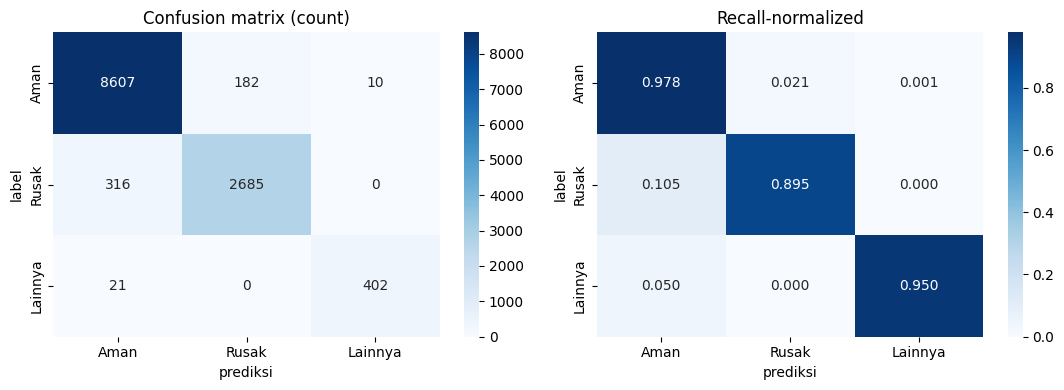

,semua train,train dgn salinan (≈60% test),train singleton (≈40% test)
model saja,0.8915,0.8581,0.9126
model + leak + kNN,0.9494,0.9451,0.9267


,ai_gen,ghtk,isocyt,n224,phone,rf512,rf640,small_web,web
n,79.0,539.0000,298.0000,253.0,20.0,2492.0000,2785.0000,1919.0000,3838.0000
akurasi,1.0,0.9647,0.8993,1.0,1.0,0.9671,0.9609,0.9265,0.9614


In [26]:
pred_oof = (L_final_oof + BIAS).argmax(1)
print(classification_report(y, pred_oof, target_names=CLASSES, digits=4))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y, pred_oof)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0]); ax[0].set_title("Confusion matrix (count)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1]); ax[1].set_title("Recall-normalized")
for a_ in ax: a_.set_xlabel("prediksi"); a_.set_ylabel("label")
plt.tight_layout(); plt.show()
sg = ~TR.has_mate.values
summary = pd.DataFrame({
    "semua train": [macro_f1(y, Loof[TR.index].argmax(1)), macro_f1(y, pred_oof)],
    "train dgn salinan (≈60% test)": [macro_f1(y[~sg], Loof[TR.index][~sg].argmax(1)), macro_f1(y[~sg], pred_oof[~sg])],
    "train singleton (≈40% test)": [macro_f1(y[sg], Loof[TR.index][sg].argmax(1)), macro_f1(y[sg], pred_oof[sg])]},
    index=["model saja", "model + leak + kNN"]).round(4)
display(summary)
per_src = pd.DataFrame({"n": TR.groupby("src").size(), "akurasi": pd.Series(pred_oof == y).groupby(TR.src.values).mean().round(4)})
display(per_src.T)

### 7.1 Koreksi shortcut & distribusi prediksi test

koreksi shortcut: 233 prediksi Rusak -> Aman  ({'isocyt': 131, 'ghtk': 102})


pred                     Aman  Rusak  Lainnya
salinan       src                            
punya salinan ai_gen       73      0        0
              ghtk        187      0        0
              isocyt       46     11        0
              n224        276      0        0
              phone        44      0        0
              rf512        26      7        0
              rf640        67    234        0
              small_web    93    173        1
              web         513     80        0
tanpa salinan ai_gen       50      0        0
              ghtk        123      0        0
              isocyt      136      0        0
              n224        244      0        0
              phone        48      0        0
              rf512        11      1        0
              rf640         5     41        0
              small_web    57    118       52
              web         261     77        2

Total: {'Aman': 2260, 'Rusak': 742, 'Lainnya': 55}


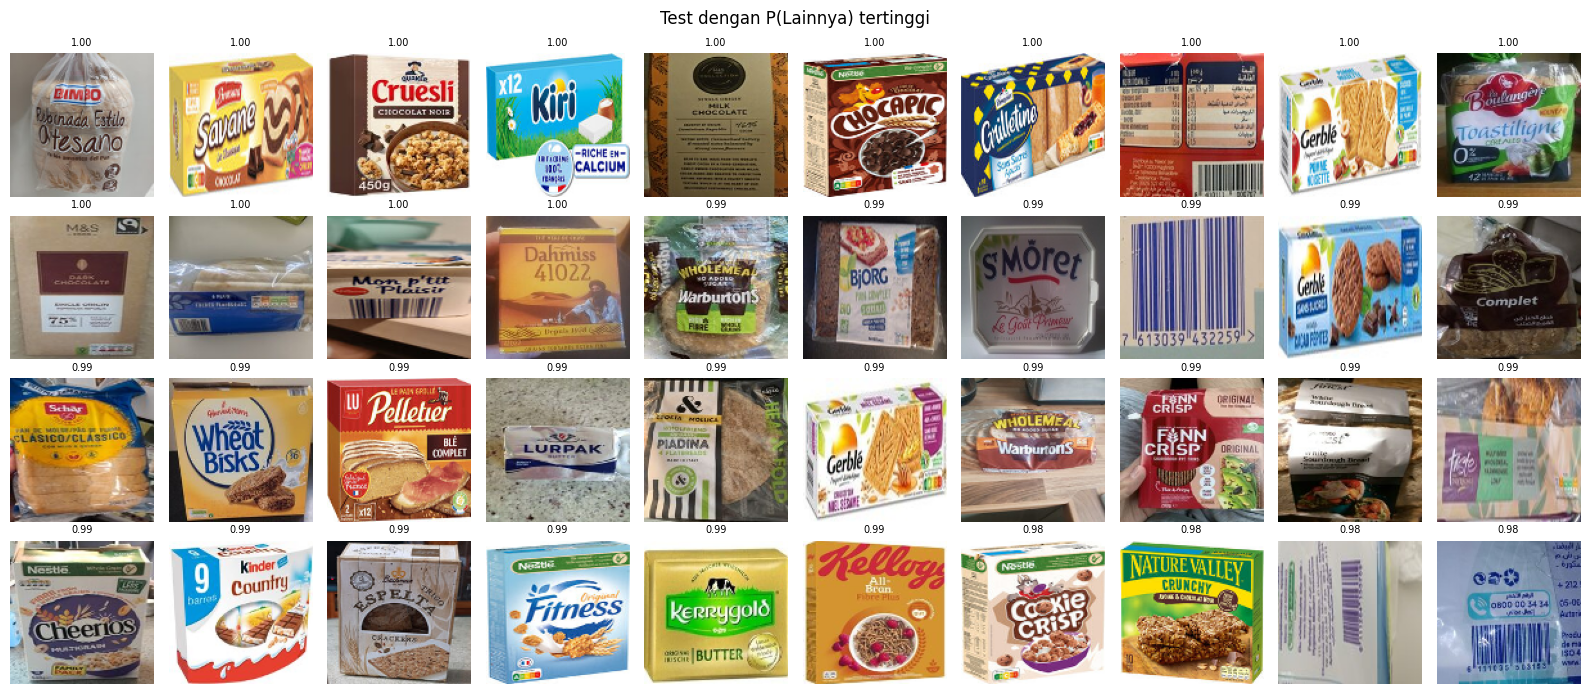

In [27]:
pred_test = (L_test[TE.index] + BIAS).argmax(1)
fix = TE.src.isin(SHORTCUT_SRC).values & ~TE.has_mate.values & (pred_test == 1)
print(f"koreksi shortcut: {fix.sum()} prediksi Rusak -> Aman  ({pd.Series(TE.src.values[fix]).value_counts().to_dict()})")
pred_test[fix] = 0
d = pd.DataFrame({"src": TE.src.values, "pred": np.array(CLASSES)[pred_test], "salinan": np.where(TE.has_mate, "punya salinan", "tanpa salinan")})
display(pd.crosstab([d.salinan, d.src], d.pred)[CLASSES])
print("Total:", d.pred.value_counts().reindex(CLASSES).to_dict())
top_l = TE.index[np.argsort(-softmax(L_test[TE.index])[:, 2])][:40]
show_grid(top_l, [f"{softmax(L_test[i:i+1])[0,2]:.2f}" for i in top_l], suptitle="Test dengan P(Lainnya) tertinggi")

### 7.1b Konsistensi grup salinan untuk koreksi shortcut
Koreksi 6.1 juga diterapkan ke citra test tanpa salinan train yang satu grup STRICT dengan citra `ghtk`/`isocyt` tanpa salinan train.

In [28]:
# (1) propagasi koreksi shortcut GHTK/isocyt ke anggota grup salinan test lain (tanpa salinan train)
_te_nomate = TE[~TE.has_mate.values]
_fixed_groups = set(_te_nomate.strict[_te_nomate.src.isin(SHORTCUT_SRC)].values)
fix_grp = (~TE.has_mate.values) & TE.strict.isin(_fixed_groups).values & (pred_test == 1)
pred_test[fix_grp] = 0
print(f"propagasi koreksi shortcut ke grup salinan: {fix_grp.sum()} prediksi Rusak -> Aman", list(TE.fname.values[fix_grp]))

propagasi koreksi shortcut ke grup salinan: 2 prediksi Rusak -> Aman ['test_00265.jpg', 'test_00327.jpg']


### 7.2 Ekspansi kelas Lainnya
Submisi diagnostik satu-kelas memberi proporsi Lainnya di test publik ±3,5% (≈107 dari 3.057 citra), sedangkan model hanya memprediksi 55. Citra `rf640` yang diprediksi Aman diurutkan dengan P(Lainnya) model + skor *label propagation* (label train), lalu K = 55 teratas diubah ke Lainnya; kandidat yang satu grup salinan dengan citra Rusak tidak diubah. Sumber `rf640` dan K divalidasi dengan skor LB publik; citra yang diubah dipilih sepenuhnya oleh kode.

rata-rata skor Lainnya (label propagation): {'Aman': 0.086, 'Lainnya': 0.97, 'Rusak': 0.04, 'TEST': 0.051}
premis: baris train yang punya salinan STRICT berlabel Rusak = 2109, di antaranya berlabel Lainnya = 0
penjaga salinan Rusak: 0 kandidat dikembalikan []
kandidat rf640 (diprediksi Aman): 72 | diubah ke Lainnya: 55
Distribusi akhir: {'Aman': 2207, 'Rusak': 740, 'Lainnya': 110}


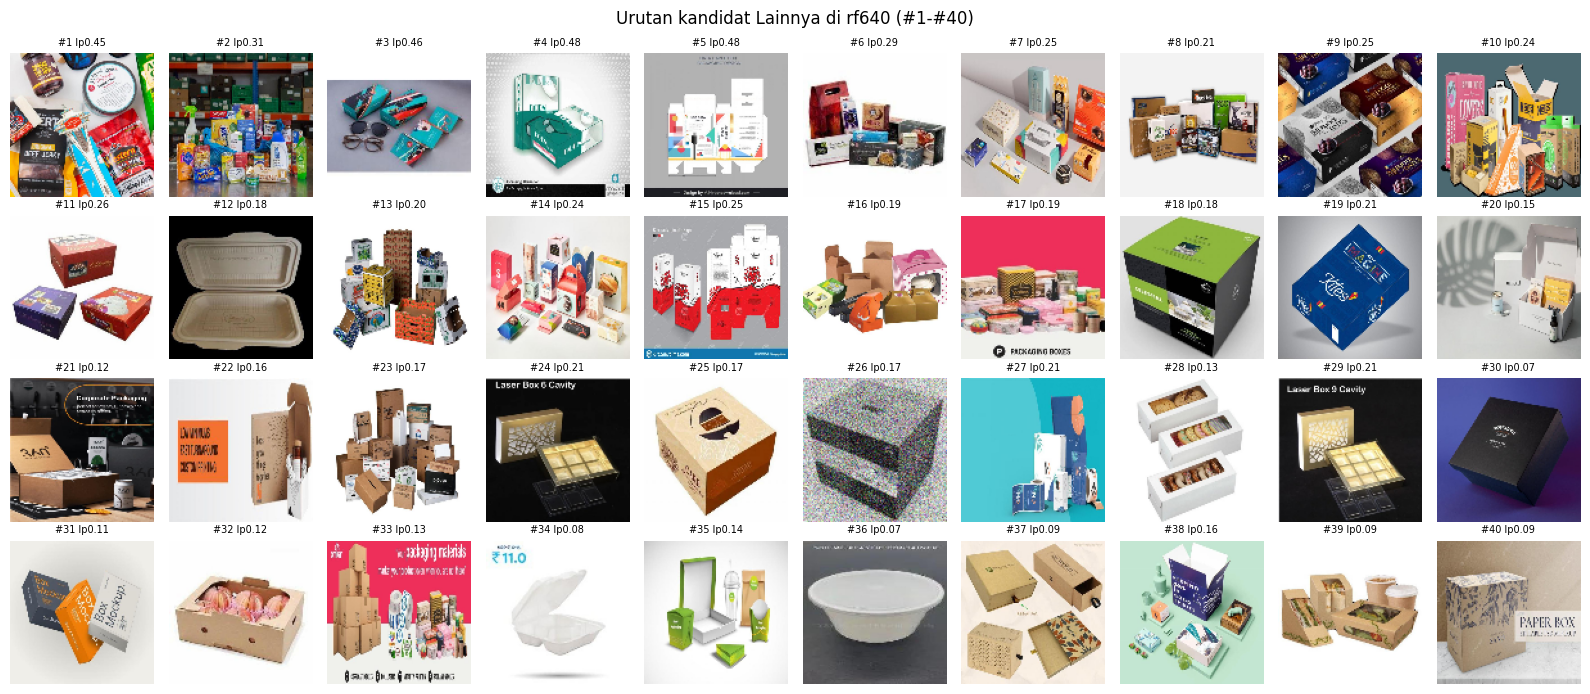

In [29]:
# Sinyal 1 = P(Lainnya) dari head yang dilatih pada label train (bagian 5-6).
# Sinyal 2 = label propagation (Zhou dkk. 2004; Iscen dkk. CVPR 2019) pada graf kNN embedding citra train+test.
from scipy.sparse import csr_matrix, diags
KLP, ALPHA_LP, IT_LP = 20, 0.9, 30
nb_i = np.zeros((N, KLP), np.int64); nb_s = np.zeros((N, KLP), np.float32)
for s in range(0, N, 2048):                                    # Ek: embedding PE-L + SigLIP2 + CLIP-H (bagian 6)
    S = (Ek[s:s + 2048] @ Ek.T).float(); r = torch.arange(s, min(s + 2048, N), device=DEVICE)
    S[torch.arange(len(r), device=DEVICE), r] = -2              # tanpa self-loop
    v, i = S.topk(KLP, 1); nb_s[s:s + 2048] = v.cpu().numpy(); nb_i[s:s + 2048] = i.cpu().numpy()
Wg = csr_matrix((np.clip(nb_s, 0, None).ravel() ** 3, (np.repeat(np.arange(N), KLP), nb_i.ravel())), shape=(N, N))
Wg = Wg + Wg.T; dg = np.asarray(Wg.sum(1)).ravel(); Dg = diags(1 / np.sqrt(dg + 1e-9)); Wn = Dg @ Wg @ Dg
Y0 = np.zeros((N, 3))
for c in range(3):
    m_ = TR.index[TR.y == c]; Y0[m_, c] = 1 / len(m_)          # normalisasi per kelas
Flp = Y0.copy()
for _ in range(IT_LP): Flp = ALPHA_LP * (Wn @ Flp) + (1 - ALPHA_LP) * Y0
lp_L = Flp[:, 2] / np.clip(Flp.sum(1), 1e-12, None)
print("rata-rata skor Lainnya (label propagation):", pd.Series(lp_L).groupby(meta.grp_name.values).mean().round(3).to_dict())

LAINNYA_SRC = ["rf640"]      # divalidasi dengan skor LB publik (lihat 7.2)
K_LAINNYA = 55               # prior matching: 55 Lainnya dari model + 55 ekspansi ≈ 107 Lainnya hasil probe
P_model = softmax(Lt)                                   # model saja (tanpa leak), rata-rata 5 fold
pred_v2 = pred_test.copy()
pool = pd.DataFrame({"idx": TE.index.values, "src": TE.src.values, "pred": pred_test, "pL": P_model[TE.index, 2], "lpL": lp_L[TE.index]})
pool = pool[(pool.pred == 0) & pool.src.isin(LAINNYA_SRC)].copy()
pool["score"] = (pool.pL.rank(pct=True) + pool.lpL.rank(pct=True)) / 2
pool = pool.sort_values(["score", "pL"], ascending=False, kind="mergesort")
pos = {i: k for k, i in enumerate(TE.index.values)}
def expand_lainnya(k):
    p = pred_v2.copy(); p[[pos[i] for i in pool.idx.values[:k]]] = 2; return p
pred_k55 = expand_lainnya(K_LAINNYA)                     # aturan versi LB publik 0,97867
# Penjaga salinan Rusak: di train TIDAK ADA citra Lainnya yang punya salinan STRICT berlabel Rusak (premis dicetak di bawah).
# Kandidat ekspansi yang grup salinannya memuat train Rusak / test yang diprediksi Rusak dikembalikan ke prediksinya (tanpa refill).
_trR = CNT[TR.index, 1] > 0
print(f"premis: baris train yang punya salinan STRICT berlabel Rusak = {int(_trR.sum())}, di antaranya berlabel Lainnya = {int((_trR & (TR.y.values == 2)).sum())}")
_g = meta.strict.values
_rus = (set(_g[TR.index.values[TR.y.values == 1]]) | set(_g[TE.index.values[pred_v2 == 1]])) - {-1}
_guard = (pred_k55 == 2) & (pred_v2 != 2) & np.isin(_g[TE.index.values], list(_rus))
pred_test = pred_k55.copy(); pred_test[_guard] = pred_v2[_guard]
print(f"penjaga salinan Rusak: {int(_guard.sum())} kandidat dikembalikan", list(TE.fname.values[_guard]))
print(f"kandidat rf640 (diprediksi Aman): {len(pool)} | diubah ke Lainnya: {K_LAINNYA}")
print("Distribusi akhir:", pd.Series(np.array(CLASSES)[pred_test]).value_counts().reindex(CLASSES).to_dict())
show_grid(pool.idx.values[:40], [f"#{k+1} lp{l:.2f}" for k, l in enumerate(pool.lpL.values[:40])], cols=10, size=1.6, suptitle="Urutan kandidat Lainnya di rf640 (#1-#40)")

### 7.3 Fine-tuning PE-Core-L
Encoder citra PE-Core-L (tanpa encoder teks) + head 3 kelas baru, fold & *anchor* sama dengan 5.3; resep di docstring `src/run_ft_vit.py`. Pada run tersimpan ini, kelima fold dimuat dari cache `artifacts/ft/pe_l224_f*.npz` yang dibuat sebelumnya di mesin ini dengan resep yang sama; tanpa cache, sel berikut melatihnya ulang.

In [30]:
%%writefile src/run_ft_vit.py
"""Fine-tuning encoder citra ViT (hanya menara visual, tanpa encoder teks) sebagai head tambahan ensemble.
Resep: 224 px, 6 epoch, AdamW lr 3e-5 dengan layer-wise lr decay 0,8 (head x10), warmup 1 epoch + cosine, EMA 0,998,
label smoothing 0,1, CE berbobot (1/frekuensi)^0,5, gradient checkpointing, augmentasi & TTA sama dengan qc_ft.
Fold notebook + anchor test fold-aware (identik dengan run_ft.py). usage: python src/run_ft_vit.py ART TAG MODEL"""
import os, sys, math, time, numpy as np, pandas as pd, torch, timm, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.transforms import v2 as T
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from qc_ft import RandomDownscale, GaussNoise, MemDS

SIZE, EPOCHS, BS, LR, LLRD, HEAD_MULT, WD, DROP_PATH, EMA_DECAY = 224, 6, 32, 3e-5, 0.8, 10.0, 0.05, 0.1, 0.998
MODEL = sys.argv[3] if len(sys.argv) > 3 else "vit_pe_core_large_patch14_336.fb"


def build_tf(train, mean, std):
    if train:
        return T.Compose([RandomDownscale(), T.RandomResizedCrop(SIZE, scale=(0.35, 1.0), ratio=(0.6, 1.66), antialias=True),
                          T.RandomHorizontalFlip(), T.RandomApply([T.RandomRotation(30)], p=0.3),
                          T.RandomApply([T.ColorJitter(0.3, 0.3, 0.3, 0.05)], p=0.6), T.RandomGrayscale(0.1),
                          T.ToImage(), T.ToDtype(torch.float32, scale=True), GaussNoise(), T.Normalize(mean, std)])
    return T.Compose([T.Resize((SIZE, SIZE), antialias=True), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std)])


@torch.no_grad()
def predict(model, cache, idx, mean, std, bs=64, workers=8):
    model.eval(); out = []
    for x, _ in DataLoader(MemDS(cache, idx, None, build_tf(False, mean, std)), batch_size=bs, num_workers=workers):
        x = x.cuda(non_blocking=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            p = model(x).float().softmax(1) + model(x.flip(3)).float().softmax(1)      # TTA hflip
        out.append((p / 2).cpu())
    return torch.cat(out).numpy()


def param_groups(model):
    """layer-wise lr decay (timm) + head x HEAD_MULT; tanpa weight decay untuk parameter 1-D / no_weight_decay."""
    from timm.optim import param_groups_layer_decay
    head = {id(p) for p in model.get_classifier().parameters()}
    nwd = set(model.no_weight_decay()) if hasattr(model, "no_weight_decay") else set()
    out = []
    for g in param_groups_layer_decay(model, weight_decay=WD, no_weight_decay_list=nwd, layer_decay=LLRD):
        body = [p for p in g["params"] if id(p) not in head]; hd = [p for p in g["params"] if id(p) in head]
        if body: out.append({"params": body, "lr_scale": g["lr_scale"], "weight_decay": g["weight_decay"]})
        if hd: out.append({"params": hd, "lr_scale": g["lr_scale"] * HEAD_MULT, "weight_decay": g["weight_decay"]})
    for g in out: g["lr"] = LR * g["lr_scale"]
    return out


def train(cache, idx, y, seed, log, workers=10):
    torch.manual_seed(seed); np.random.seed(seed)
    model = timm.create_model(MODEL, pretrained=True, num_classes=3, drop_path_rate=DROP_PATH, img_size=SIZE)
    model.set_grad_checkpointing(True); model = model.cuda()
    pc = model.pretrained_cfg; mean, std = tuple(pc["mean"]), tuple(pc["std"])
    cnt = np.maximum(np.bincount(y, minlength=3), 1); cw = torch.tensor((cnt.sum() / cnt) ** 0.5, dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=(cw / cw.mean()).cuda(), label_smoothing=0.1)
    dl = DataLoader(MemDS(cache, idx, y, build_tf(True, mean, std)), batch_size=BS, shuffle=True, drop_last=True,
                    num_workers=workers, pin_memory=True, persistent_workers=True)
    opt = torch.optim.AdamW(param_groups(model), lr=LR, weight_decay=WD)
    total, warm = EPOCHS * len(dl), len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1, s / total))))
    from timm.utils import ModelEmaV3
    ema = ModelEmaV3(model, decay=EMA_DECAY, use_warmup=True, device="cuda"); step = 0
    for ep in range(EPOCHS):
        model.train(); t = time.time(); tot = 0
        for x, yb in dl:
            x = x.cuda(non_blocking=True); yb = yb.cuda(non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16): logits = model(x).float()
            loss = crit(logits, yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
            ema.update(model, step=step); step += 1; tot += loss.item()
        log(f"ep{ep + 1}/{EPOCHS} loss={tot / len(dl):.4f} {time.time() - t:.0f}s")
    return ema.module, mean, std


if __name__ == "__main__":
    ART, TAG = sys.argv[1], sys.argv[2]
    torch.backends.cudnn.benchmark = True; torch.backends.cuda.matmul.allow_tf32 = True
    m = pd.read_csv(f"{ART}/ft_folds.csv"); cache = f"{ART}/cache448.npy"
    TR = m[(m.split == "train") & m.ok]; TE = m[m.split == "test"]; anc = TE[TE.una & (TE.fold >= 0)]
    for f in range(5):
        out = f"{ART}/ft/{TAG}_f{f}.npz"
        if os.path.exists(out): print(f"[fold{f}] cache ada, dilewati", flush=True); continue
        trn = pd.concat([TR[TR.fold != f], anc[anc.fold != f]])                    # anchor fold-aware
        ytr = np.where(trn.split == "train", trn.y, trn.leak_y).astype(int)
        va = TR[TR.fold == f]
        model, mean, std = train(cache, trn.idx.values, ytr, seed=f, log=lambda s: print(f"[fold{f}] {s}", flush=True))
        pv = predict(model, cache, va.idx.values, mean, std); pt = predict(model, cache, TE.idx.values, mean, std)
        np.savez(out, val_idx=va.idx.values, val_prob=pv, test_idx=TE.idx.values, test_prob=pt)
        print(f"[fold{f}] selesai", flush=True); del model; torch.cuda.empty_cache()


Writing src/run_ft_vit.py


In [31]:
VIT_HEADS = {  # tag: model timm (bobot di ensemble dipilih dengan nested CV di 7.4)
    "pe_l224": "vit_pe_core_large_patch14_336.fb",
}
vit_oof, vit_tef = {}, {}
gc.collect(); torch.cuda.empty_cache()   # lepaskan cache VRAM kernel sebelum fine-tuning di subprocess
for tag, model_name in VIT_HEADS.items():
    proc = subprocess.run([sys.executable, "src/run_ft_vit.py", ART, tag, model_name], capture_output=True, text=True)
    print("\n".join(l for l in proc.stdout.splitlines() if "ep6/" in l or "selesai" in l or "dilewati" in l))
    assert proc.returncode == 0, proc.stderr[-3000:]
    _o = np.full((N, 3), 1 / 3, np.float32); _t = np.full((5, N, 3), 1 / 3, np.float32)
    for f in range(5):
        z = np.load(f"{ART}/ft/{tag}_f{f}.npz"); _o[z["val_idx"]] = z["val_prob"]; _t[f, z["test_idx"]] = z["test_prob"]
    vit_oof[tag], vit_tef[tag] = _o, _t
    print(f"OOF fine-tune {tag} saja: {macro_f1(TR.y.values, _o[TR.index].argmax(1)):.4f}")


[fold0] cache ada, dilewati
[fold1] cache ada, dilewati
[fold2] cache ada, dilewati
[fold3] cache ada, dilewati
[fold4] cache ada, dilewati
OOF fine-tune pe_l224 saja: 0.8859


### 7.4 Ensemble final
PE-Core-L ditambahkan ke ensemble (bobot dari grid kecil berdasarkan nested OOF); transfer label memakai grup LOOSE bila tak ada salinan STRICT, dan kNN soft-vote diseimbangkan per kelas. Hanya keputusan Aman/Rusak yang berubah; prediksi Lainnya dari 7.2 tetap.

In [32]:
# 7.4 Ensemble v3 + post-processing v2 untuk keputusan Aman/Rusak; set Lainnya hasil bagian 7.2 DIKUNCI.
# (1) ensemble: LR + MLP + ConvNeXt-CL (W_FTCL) + head fine-tune ViT (7.3); bobot head ViT dipilih dengan nested CV (grid kecil)
# (2) leak dari grup STRICT; citra tanpa salinan STRICT memakai grup LOOSE (fallback)
# (3) kNN soft-vote dengan koreksi prior kelas (class-balanced) + grid gk/beta lebih halus
# (4) parameter post-processing di-tune dengan nested CV (tune 4 fold, evaluasi fold ke-5); bobot head ViT dipilih dari nested OOF yang sama
# (5) koreksi shortcut GHTK/isocyt + propagasinya diterapkan lagi; prediksi Lainnya (native + ekspansi rf640) tidak diubah
_lg = lambda a: np.log(np.clip(a, 1e-6, 1))
pred_base = pred_k55.copy()                                    # versi sebelumnya (LB publik 0,97867)
pred_guard = pred_test.copy()                                  # + penjaga salinan Rusak (7.2)
_base_mem = [(1.0, oof_lr, tef_lr), (1.0, oof_mlp, tef_mlp)] + ([(W_FTCL, oof_ftcl, tef_ftcl)] if W_FTCL > 0 else [])
def _ensemble(wv):                                             # wv = bobot tiap head ViT (urutan VIT_HEADS)
    mem = _base_mem + [(w, vit_oof[t], vit_tef[t]) for t, w in zip(VIT_HEADS, wv)]; s = sum(m[0] for m in mem)
    return sum(w * _lg(o) for w, o, _ in mem) / s, (sum(w * _lg(t) for w, _, t in mem) / s).mean(0)

meta["loose"] = dups.loose_group.values
def _loo_counts_col(col):
    trm = (meta.split == "train").values & OK; yy = meta.y.values
    codes = pd.factorize(meta[col].values)[0]; M = np.zeros((codes.max() + 1, 3))
    np.add.at(M, (codes[trm], yy[trm]), 1)
    c = M[codes].copy(); c[trm, yy[trm]] -= 1; c[~OK] = 0
    return c
CNT_LOOSE = _loo_counts_col("loose")
CNT2 = np.where((CNT.sum(1) > 0)[:, None], CNT, CNT_LOOSE)     # STRICT, fallback LOOSE
_prior = np.bincount(y, minlength=3) / len(y)
def _knn_lp(beta, balance):
    w = np.exp(beta * (ksims - 1)); P = np.stack([(w * (klabs == c)).sum(1) for c in range(3)], 1) + 1e-3
    if balance: P = P / _prior[None, :]
    return np.log(P / P.sum(1, keepdims=True))

class PostProc:
    """leak blending + kNN soft-vote (prioritas leak, lambda grup konflik), di-tune berurutan seperti bagian 6."""
    def __init__(self, cnt, balance, gk_grid, beta_grid):
        self.cnt = cnt; tot = cnt.sum(1); has = tot > 0; una = has & ((cnt > 0).sum(1) == 1)
        self.conf = has & ~una; self.kmask = np.where(una, 0.0, 1.0)[:, None]
        self.gk_grid, self.beta_grid = gk_grid, beta_grid; self.KLP = {b: _knn_lp(b, balance) for b in beta_grid}
    def leak(self, idx, g, a, lam): return leak_logit(self.cnt[idx], g, a) * np.where(self.conf[idx], lam, 1.0)[:, None]
    def fit(self, L0, rows):
        yy = meta.y.values[rows]; L0r = L0[rows]; best = (macro_f1(yy, L0r.argmax(1)), 0, 1)
        for g, a in itertools.product([0.5, 1, 2, 3, 5, 8], [0.05, 0.2, 0.5, 1.0]):
            s = macro_f1(yy, (L0r + leak_logit(self.cnt[rows], g, a)).argmax(1))
            if s > best[0]: best = (s, g, a)
        g, a = best[1], best[2]; bk = (-1, 1.0, 0.0, self.beta_grid[0])
        for lam in [1.0, 0.5, 0.25, 0.0]:
            L2 = L0r + self.leak(rows, g, a, lam); bl = (macro_f1(yy, L2.argmax(1)), 0.0, self.beta_grid[0])
            for gk, b in itertools.product(self.gk_grid, self.beta_grid):
                s = macro_f1(yy, (L2 + gk * self.kmask[rows] * self.KLP[b][rows]).argmax(1))
                if s > bl[0]: bl = (s, gk, b)
            if bl[0] > bk[0]: bk = (bl[0], lam, bl[1], bl[2])
        return dict(GAM=g, ALP=a, LAM=bk[1], GK=bk[2], BETA=bk[3])
    def apply(self, L0, idx, P):
        return L0[idx] + self.leak(idx, P["GAM"], P["ALP"], P["LAM"]) + P["GK"] * self.kmask[idx] * self.KLP[P["BETA"]][idx]
    def nested(self, L0):
        rows = TR.index.values; f_ = TR.fold.values; pred = np.zeros(len(rows), int)
        for f in range(5):
            P = self.fit(L0, rows[f_ != f]); pred[f_ == f] = self.apply(L0, rows[f_ == f], P).argmax(1)
        return pred

_FG = (0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0); _B4 = (20, 40, 80, 160)
PP_OLD = PostProc(CNT, False, (0.25, 0.5, 1.0, 1.5, 2.0), (20, 40, 80))      # pipeline bagian 6
PP_NEW = PostProc(CNT2, True, _FG, _B4)                                       # post-processing v2

# bobot head ViT: grid kecil, dipilih dengan nested OOF macro-F1 pipeline v3 lengkap (seri -> bobot terkecil)
_wrows = []
for _wv in itertools.product((0.5, 1.0, 1.5, 2.0, 3.0), repeat=len(VIT_HEADS)):
    _wrows.append({**dict(zip(VIT_HEADS, _wv)), "nested OOF": macro_f1(y, PP_NEW.nested(_ensemble(_wv)[0]))})
_wt = pd.DataFrame(_wrows); W_VIT = tuple(float(v) for v in _wt.loc[_wt["nested OOF"].idxmax(), list(VIT_HEADS)])
display(_wt.round(4))
print("bobot head ViT terpilih:", dict(zip(VIT_HEADS, W_VIT)))
Loof3, Lt3 = _ensemble(W_VIT)

_sg = ~TR.has_mate.values; _cf = (TR.has_mate & ~TR.una).values
_rows = []
for name, L0, pp in [("lama: ensemble bagian 6 + post-processing lama", Loof, PP_OLD),
                     ("ensemble v3 + post-processing lama", Loof3, PP_OLD),
                     ("ensemble bagian 6 + post-processing v2", Loof, PP_NEW),
                     ("ensemble v3 + post-processing v2", Loof3, PP_NEW)]:
    p_ = pp.nested(L0)
    _rows.append({"varian": name, "nested OOF": macro_f1(y, p_), "nested OOF tanpa salinan": macro_f1(y[_sg], p_[_sg]),
                  "nested OOF grup konflik": macro_f1(y[_cf], p_[_cf]), "error": int((p_ != y).sum())})
display(pd.DataFrame(_rows).set_index("varian").round(4))

PARAMS_V3 = PP_NEW.fit(Loof3, TR.index.values)
L_test3 = PP_NEW.apply(Lt3, np.arange(N), PARAMS_V3)
_tm = temask & ~meta.has_mate.values                                         # konsistensi grup test-only (seperti bagian 6)
for _, gg in pd.DataFrame({"g": meta.strict.values[_tm], "i": np.where(_tm)[0]}).groupby("g"):
    if len(gg) > 1: L_test3[gg.i.values] = L_test3[gg.i.values].mean(0, keepdims=True)
pred_ar = L_test3[TE.index].argmax(1)
_fx = TE.src.isin(SHORTCUT_SRC).values & ~TE.has_mate.values & (pred_ar == 1); pred_ar[_fx] = 0          # koreksi shortcut (6.1)
_fg = (~TE.has_mate.values) & TE.strict.isin(_fixed_groups).values & (pred_ar == 1); pred_ar[_fg] = 0    # propagasi (7.1b)
def _lock(base):                                                             # set Lainnya dikunci
    out = base.copy(); m = (base != 2) & (pred_ar != 2); out[m] = pred_ar[m]; return out
pred_v3 = _lock(pred_guard); pred_v3_noguard = _lock(pred_base)
_exp = (pred_guard == 2) & (pred_v2 != 2)                                     # ekspansi rf640 (tetap dikunci)
pred_v3_free = pred_ar.copy(); pred_v3_free[_exp] = 2                        # varian: Lainnya native mengikuti ensemble v3
print("varian 'free' (Lainnya native mengikuti v3): Lainnya keluar", int(((pred_v3 == 2) & (pred_v3_free != 2)).sum()),
      "| Lainnya masuk", int(((pred_v3 != 2) & (pred_v3_free == 2)).sum()), "| sumber:", pd.Series(TE.src.values[pred_v3 != pred_v3_free]).value_counts().to_dict())
_ch = pred_v3 != pred_base
print("parameter v2:", PARAMS_V3, "| prediksi berubah vs versi 0,97867:", int(_ch.sum()))
if _ch.any():
    display(pd.DataFrame({"src": TE.src.values[_ch], "salinan": np.where(TE.has_mate.values[_ch], np.where(TE.una.values[_ch], "seragam", "konflik"), "tanpa"),
                          "dari": np.array(CLASSES)[pred_base[_ch]], "ke": np.array(CLASSES)[pred_v3[_ch]]}).value_counts().rename("n").to_frame())
print("Distribusi:", pd.Series(np.array(CLASSES)[pred_v3]).value_counts().reindex(CLASSES).to_dict())


,pe_l224,nested OOF
0,0.5,0.9484
1,1.0,0.9493
2,1.5,0.9515
3,2.0,0.9523
4,3.0,0.9522


bobot head ViT terpilih: {'pe_l224': 2.0}


,nested OOF,nested OOF tanpa salinan,nested OOF grup konflik,error
varian,,,,
lama: ensemble bagian 6 + post-processing lama,0.9455,0.9156,0.6823,576
ensemble v3 + post-processing lama,0.9491,0.9248,0.6911,536
ensemble bagian 6 + post-processing v2,0.9476,0.9188,0.7084,549
ensemble v3 + post-processing v2,0.9523,0.9315,0.7077,507


varian 'free' (Lainnya native mengikuti v3): Lainnya keluar 0 | Lainnya masuk 0 | sumber: {}
parameter v2: {'GAM': 2, 'ALP': 0.05, 'LAM': 0.5, 'GK': 0.25, 'BETA': 20} | prediksi berubah vs versi 0,97867: 16


n
src       salinan dari  ke      
rf640     konflik Aman  Rusak  6
web       tanpa   Aman  Rusak  2
          konflik Aman  Rusak  2
ai_gen    tanpa   Aman  Rusak  1
n224      tanpa   Aman  Rusak  1
small_web tanpa   Aman  Rusak  1
rf640     konflik Rusak Aman   1
small_web tanpa   Rusak Aman   1
web       konflik Rusak Aman   1

Distribusi: {'Aman': 2197, 'Rusak': 750, 'Lainnya': 110}


In [33]:
# Pilihan submission final: versi v3. Versi sebelumnya (LB publik 0,97867) dan komponennya tetap ditulis sebagai varian (8.1).
pred_test = pred_v3.copy()
print("submission.csv = versi v3 | berbeda dari versi 0,97867 pada", int((pred_test != pred_base).sum()), "citra")


submission.csv = versi v3 | berbeda dari versi 0,97867 pada 16 citra


## 8. Submission

In [34]:
sub = pd.DataFrame({"filename": TE.fname.values, "label": np.array(CLASSES)[pred_test]})
ss = pd.read_csv(f"{DATA}/sample_submission.csv")
sub = ss[["filename"]].merge(sub, on="filename", how="left")
assert len(sub) == 3057 and sub.label.notna().all() and set(sub.label) <= set(CLASSES)
os.makedirs(f"{ROOT}/submissions", exist_ok=True)
sub.to_csv(f"{ROOT}/submission.csv", index=False); sub.to_csv(f"{ROOT}/submissions/sub_nb_final.csv", index=False)
sub_v2 = ss[["filename"]].merge(pd.DataFrame({"filename": TE.fname.values, "label": np.array(CLASSES)[pred_v2]}), on="filename")
sub_v2.to_csv(f"{ROOT}/submissions/sub_nb_v2.csv", index=False)      # versi sebelum ekspansi Lainnya (LB 0,88794)
print(sub.label.value_counts()); display(sub.head())

label
Aman       2197
Rusak       750
Lainnya     110
Name: count, dtype: int64


,filename,label
0,test_00001.jpg,Aman
1,test_00002.jpg,Aman
2,test_00003.jpg,Rusak
3,test_00004.jpg,Aman
4,test_00005.jpeg,Aman


### 8.1 Varian
`submission.csv` = `sub_nb_v3`; varian pembanding (termasuk nilai K lain untuk ekspansi Lainnya) ditulis ke `submissions/`.

In [35]:
def write_variant(pred, name):
    v = ss[["filename"]].merge(pd.DataFrame({"filename": TE.fname.values, "label": np.array(CLASSES)[pred]}), on="filename")
    v.to_csv(f"{ROOT}/submissions/{name}.csv", index=False); return v.label.value_counts().to_dict()
print("sub_nb_base_097867:", write_variant(pred_base, "sub_nb_base_097867"))      # versi sebelumnya (LB publik 0,97867)
print("sub_nb_guard:", write_variant(pred_guard, "sub_nb_guard"))                    # 0,97867 + penjaga salinan Rusak
print("sub_nb_v3_noguard:", write_variant(pred_v3_noguard, "sub_nb_v3_noguard"))    # 0,97867 + perbaikan Aman/Rusak (7.3-7.4)
print("sub_nb_v3:", write_variant(pred_v3, "sub_nb_v3"))                              # = submission.csv
print("sub_nb_v3_free:", write_variant(pred_v3_free, "sub_nb_v3_free"))                # v3 + Lainnya native mengikuti ensemble v3 (opsional)
for k in [45, 65, len(pool)]:
    print(f"cand_rf640_k{k}:", write_variant(expand_lainnya(k), f"cand_rf640_k{k}"))

sub_nb_base_097867: {'Aman': 2207, 'Rusak': 740, 'Lainnya': 110}
sub_nb_guard: {'Aman': 2207, 'Rusak': 740, 'Lainnya': 110}
sub_nb_v3_noguard: {'Aman': 2197, 'Rusak': 750, 'Lainnya': 110}
sub_nb_v3: {'Aman': 2197, 'Rusak': 750, 'Lainnya': 110}
sub_nb_v3_free: {'Aman': 2197, 'Rusak': 750, 'Lainnya': 110}
cand_rf640_k45: {'Aman': 2217, 'Rusak': 740, 'Lainnya': 100}
cand_rf640_k65: {'Aman': 2197, 'Rusak': 740, 'Lainnya': 120}
cand_rf640_k72: {'Aman': 2190, 'Rusak': 740, 'Lainnya': 127}
